<a href="https://colab.research.google.com/github/2303880-Mandi/Bridging-Theory-and-Practice-in-Kernel-Based-Dequantization-of-VQML/blob/main/KTA_Final_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Re-weighting experiments over several target degrees
Follows your pipeline: **1** target → **2** PQC → **3** sample → **4** train → **5** spectrum from the *trained* PQC (+FFT check) → **6** feature map → **7** choose w (guesses, then KTA) → **8** re-weighted kernel → **9** KRR sweep over M.

**Code:** `build_random_pqc`, `square_loss`, the Adam training loop, `check_spectrum_numerically`, `get_omega_D` / `extract_c_omega` / `split_a_b` / `build_feature_map` / `extract_pqc_feature_map`, `build_w`, and the KTA objective.

**Target, PQC and variants:** the target is now the real (a, b) form of Eq. (21), f(x) = <c, phi_D(x)> with a unit-norm c (section 2), the PQC uses 5 trainable layers per block as in your notebook, and the weight variants are the 7 from your script plus the KTA-learned w.

**What is different, and the switch for each:**
- `FAST` (config): evaluates the PQC on a whole batch of x in one call instead of a Python loop. Same numbers; section 3 proves it. `FAST = False` runs your per-sample loop exactly.
- The kernel matrix and the KTA ingredients are computed with matrix products instead of loops/huge 3-D arrays (needed for M in the thousands). Section 3 checks them against your original functions.
- Training samples for KRR are a random nested subset of a dense grid, and RMSE is measured on the held-out grid points (see config comments).
- **Three target types** (`CASES`): concentrated (only 10% of the coefficients non-zero), random (every coefficient random) and uniform (every coefficient the same). Every plot category gives one 2 x 3 figure per target type (6 panels = the 6 degrees).
- RMSE is swept up to M = `MAX_M` = 400 training samples; no vertical reference lines in the error plots.
- Every plot category has its own cell, and each cell draws three 2 x 3 figures (one per target type, one panel per degree).

## 0. Install and imports

In [ ]:
!pip install pennylane -q

In [ ]:
import math, time, io, contextlib, warnings
import pennylane as qml
from pennylane import numpy as np                 # PennyLane numpy, as in your notebook
import numpy as onp                               # plain NumPy for the classical parts
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from pennylane.templates import StronglyEntanglingLayers
from pennylane.fourier import mark
from datetime import datetime
warnings.filterwarnings("ignore", category=UserWarning)

## 1. Configuration (everything you may want to change is here)

In [ ]:
# ---- targets and PQC ------------------------------------------------------------------------------
DEGREES      = [50, 75, 150, 200, 250, 300]     # target degrees
CASES        = ["concentrated", "random", "uniform"]   # the three target types (see make_target_nb)
CASE_LABEL   = {"concentrated": "Concentrated (10% non-zero)", "random": "Random coefficients", "uniform": "Uniform (equal coefficients)"}
CONC_FRAC    = 0.10                             # concentrated case: fraction of the `degree` coefficients that are non-zero
N_NONZERO    = lambda D: max(1, round(CONC_FRAC * D))
TARGET_SEED  = 7                                # seed of the target coefficients
NUM_QUBITS   = 5                                # fixed. Only the number of encoding layers r grows: r = ceil(degree / (3 * 5))
TRAINABLE_BLOCK_LAYERS = 5                      # as in your notebook
# ---- training (your values) -----------------------------------------------------------------------
MAX_STEPS, BATCH_SIZE, LEARNING_RATE = 100, 25, 0.003
TRAIN_SAMPLING = "fresh"                      # "grid100": minibatches from the fixed 100-point grid (your pipeline). "fresh": new random x in [-6, 6] at every step (no aliasing for high degree)
SEED         = 42
FAST         = True                             # True: batched circuit calls (same numbers). False: your per-sample loop (hours, see section 3)
# ---- KRR ------------------------------------------------------------------------------------------
LAM          = 1e-6                             # ridge strength (your pipeline)
M_FRACTIONS  = (0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1, 1.25, 1.5, 2, 3, 4, 6)   # M = fraction * (PQC degree); only M <= MAX_M is kept
MAX_M        = 400                              # the RMSE sweeps end here (400 is always included as the last point)
MIN_M        = 10                               # smallest training-set size
POOL_PER_DEG = 10                               # KRR sample pool = evaluation grid = 10 * (PQC degree) points on [-6, 6]
                                                # (the 100-point grid is too coarse to carry a degree-250 kernel; the PQC itself still trains on 100 points)
# ---- weight guesses -------------------------------------------------------------------------------
FLOOR            = 0.05                         # weight given to frequencies a guess does not mention (never fully switched off)
# ---- plots ----------------------------------------------------------------------------------------
FIT_VIEW     = "grid100"                        # "grid100": full [-6, 6] on your 100 points joined by lines (your style); "zoom": dense, narrow window
LOG_Y        = False
PAIRS        = [(c, d) for c in CASES for d in DEGREES]   # every (target type, degree) combination
SAVE_DIR     = None                             # e.g. "figures" -> every figure is also saved as a 300-dpi PNG

In [ ]:
def pqc_eval(circuit, weights, xs):
    """Evaluate the PQC at many inputs.
    FAST=True : one batched circuit call (PennyLane broadcasting) -- identical values to the loop.
    FAST=False: your per-sample list comprehension."""
    if FAST:
        return circuit(weights, np.array(xs, requires_grad=False))
    return [circuit(weights, x_) for x_ in xs]

In [ ]:
def build_random_pqc(mode, num_qubits, num_layers, trainable_block_layers=1, seed=None,
                      encode_prob=0.7):
    """
    Build a parametrised quantum circuit (PQC) as a Fourier-type model,
    following Schuld, Sweke & Meyer (2021).

    mode : {"parallel", "sequential", "random"}
        "parallel"   -> L = 1 layer; S(x) applied once across all qubits.
        "sequential" -> L = num_layers; S(x) (RX on every qubit) repeated in series.
        "random"     -> L = num_layers; at EACH layer, a random subset of qubits gets
                        an encoding gate, each independently and randomly RX, RY, or RZ
                        (with probability `encode_prob` per qubit per layer). The random
                        structure is drawn ONCE at build time (fixed for this circuit
                        instance), not re-randomized on every call.
    encode_prob : float
        Only used for mode="random". Probability that a given qubit receives an
        encoding gate in a given layer.
    """
    if mode not in ("parallel", "sequential", "random"):
        raise ValueError("mode must be 'parallel', 'sequential', or 'random'")

    if seed is not None:
        np.random.seed(seed)

    dev = qml.device("default.qubit", wires=num_qubits)

    def S(x):
        """Data encoding layer: RX(x) on every qubit, all tagged 'x'."""
        for i in range(num_qubits):
            mark(qml.RX(x, wires=i), "x")
            mark(qml.RY(x, wires=i), "x")
            mark(qml.RZ(x, wires=i), "x")

    def W(theta):
        """Trainable layer with weights theta."""
        StronglyEntanglingLayers(theta, wires=range(num_qubits))

    if mode == "parallel":
        num_blocks = 1
        block_layers = num_layers if num_layers else 1

    elif mode == "sequential":
        num_blocks = num_layers
        block_layers = trainable_block_layers

    else:  # mode == "random"
        num_blocks = num_layers
        block_layers = trainable_block_layers

        # --- Draw the random encoding blueprint ONCE, at build time ---
        # blueprint[layer] = list of (qubit_index, gate_class) to apply that layer
        # Every qubit gets an encoding gate in every layer; only the GATE TYPE is random.
        rng = np.random.default_rng(seed)
        gate_choices = [qml.RX]  #, qml.RY, qml.RZ]
        blueprint = []
        for l in range(num_blocks):
            layer_gates = []
            for q in range(num_qubits):
                gate_cls = gate_choices[rng.integers(0, len(gate_choices))]
                layer_gates.append((q, gate_cls))
            blueprint.append(layer_gates)

        print("Random encoding blueprint (layer -> [(qubit, gate), ...]):")
        for l, layer_gates in enumerate(blueprint):
            readable = [(q, g.__name__) for q, g in layer_gates]
            print(f"  layer {l}: {readable}")

        def S_random(x, layer_gates):
            """Apply this layer's encoding gates (every qubit), all tagged 'x'."""
            for q, gate_cls in layer_gates:
                mark(gate_cls(x, wires=q), "x")


    @qml.qnode(dev)
    def circuit(weights, x):
        """U(x) = W^(L+1) S(x) W^(L) ... S(x) W^(1)."""
        for l in range(num_blocks):
            W(weights[l])
            if mode == "random":
                S_random(x, blueprint[l])
            else:
                S(x)
        W(weights[num_blocks])
        obs = qml.PauliZ(0)
        for i in range(1, num_qubits):
          obs = obs @ qml.PauliZ(i)

        return qml.expval(obs)


    weights = 2 * np.pi * np.random.random(
        size=(num_blocks + 1, block_layers, num_qubits, 3), requires_grad=True
    )

    return circuit, weights, dev

In [ ]:
def square_loss(targets, predictions):
    loss = 0
    for t, p in zip(targets, predictions):
        loss += (t - p) ** 2
    loss = loss / len(targets)
    return 0.5 * loss

In [ ]:


def make_target_nb(degree, case="concentrated", keep_c0=True, seed=TARGET_SEED):
    """Target in the real (a, b) form of Eq. (21):  f(x) = < c, phi_D(x) >,
         c      = (c0, a_1, b_1, ..., a_D, b_D) / ||c||_2     (unit Euclidean norm)
         phi_D  = (1, cos x, sin x, ..., cos Dx, sin Dx) / sqrt(|Omega_D|),   |Omega_D| = degree + 1   (Eq. 23, as in your feature map)
       |f(x)| <= 1 by Cauchy-Schwarz (||c|| = 1, ||phi_D(x)|| = 1). Only frequencies 0..degree are used.
       "concentrated": N_NONZERO(degree) distinct random frequencies carry random real (a_n, b_n); all others are exactly 0
       "random"      : every frequency 1..degree gets its own random real (a_n, b_n)
       "uniform"     : c0 and every a_n, b_n equal 1/sqrt(2*degree + 1)"""
    rng = np.random.default_rng(seed)
    a = np.zeros(degree); b = np.zeros(degree)

    if case == "concentrated":
        n_nonzero = N_NONZERO(degree)
        active = rng.choice(np.arange(1, degree + 1), size=n_nonzero, replace=False)
        a[active - 1] = rng.uniform(-1, 1, n_nonzero)
        b[active - 1] = rng.uniform(-1, 1, n_nonzero)
        c0 = rng.uniform(-1, 1) if keep_c0 else 0.0
    elif case == "random":
        a[:] = rng.uniform(-1, 1, degree)
        b[:] = rng.uniform(-1, 1, degree)
        c0 = rng.uniform(-1, 1) if keep_c0 else 0.0
    elif case == "uniform":
        a[:] = 1.0; b[:] = 1.0
        c0 = 1.0 if keep_c0 else 0.0
    else:
        raise ValueError(case)

    norm = np.sqrt(c0 ** 2 + np.sum(a ** 2) + np.sum(b ** 2))      # Euclidean norm of (c0, a_1, b_1, ...)
    a, b, c0 = a / norm, b / norm, c0 / norm
    omegas = np.arange(1, degree + 1, dtype=float)
    inv_sqrt_omega = 1.0 / np.sqrt(degree + 1)                      # 1/sqrt(|Omega_D|) from phi_D

    coeffs  = [complex(ai, bi) for ai, bi in zip(a, b)]             # |coeffs[n-1]| = sqrt(a_n^2 + b_n^2)
    scaling = 1

    # (coeffs, coeff0, scaling) stay the only defaults, so cell 23's `... = target_function.__defaults__` still works
    def target_function(x, _coeffs=coeffs, _coeff0=c0, _scaling=scaling):
        x_arr = np.atleast_1d(np.asarray(x, dtype=float))
        wx = x_arr[:, None] * omegas[None, :]
        out = inv_sqrt_omega * (c0 + np.cos(wx) @ a + np.sin(wx) @ b)
        return out if np.ndim(x) else float(out[0])
    target_function.a, target_function.b = a, b
    return target_function

In [ ]:
def train_pqc(PQC_circuit, weights, x, target_y, target_function=None):
    """Your cell-16 training loop (square loss, Adam, batches), wrapped in a function.
    TRAIN_SAMPLING = "grid100": minibatches drawn from the fixed grid x (your pipeline)
    TRAIN_SAMPLING = "fresh"  : every step draws BATCH_SIZE new random points in [-6, 6] and evaluates the target there
    The cost that is recorded (cst) is always on the fixed 100-point grid, so both options are comparable."""
    def cost(weights, x, y):
        predictions = pqc_eval(PQC_circuit, weights, x)
        if FAST:
            return 0.5 * np.mean((y - predictions) ** 2)      # = square_loss, vectorised (checked in section 3)
        return square_loss(y, predictions)                   # your loss, unchanged

    opt = qml.AdamOptimizer(LEARNING_RATE)
    cst = [float(cost(weights, x, target_y))]                 # initial cost
    for step in range(MAX_STEPS):
        if TRAIN_SAMPLING == "fresh":
            x_batch = np.array(np.random.uniform(-6, 6, BATCH_SIZE), requires_grad=False)
            y_batch = np.array(target_function(x_batch), requires_grad=False)
        else:
            batch_index = np.random.randint(0, len(x), (BATCH_SIZE,))
            x_batch, y_batch = x[batch_index], target_y[batch_index]
        weights, _, _ = opt.step(cost, weights, x_batch, y_batch)
        cst.append(float(cost(weights, x, target_y)))
    return weights, cst


In [ ]:
def check_spectrum_numerically(build_fn, weights, omega, title, threshold=1e-3):
    """
    threshold is now RELATIVE: a frequency counts as 'non-zero' if
    |c_n| > threshold * max|c_n|.
    """
    omega_int = np.unique(np.round(np.asarray(omega, dtype=float)).astype(int))
    D = int(np.max(np.abs(omega_int)))          # degree of the analytic spectrum

    N = 2 * D + 2                               # >= 2D+1 samples -> no aliasing for a band-limited model
    xs = np.linspace(0, 2 * np.pi, N, endpoint=False)

    expectation_values = np.array(pqc_eval(build_fn, weights, xs))   # CHANGED: was a per-sample list comprehension

    fft_coeffs = np.fft.fft(expectation_values) / N
    n_index = np.fft.fftfreq(N, d=1.0 / N).astype(int)
    order = np.argsort(n_index)
    n_sorted, c_sorted = n_index[order], fft_coeffs[order]
    mag_sorted = np.abs(c_sorted)

    empirical_freqs = n_sorted[mag_sorted > threshold * mag_sorted.max()]
    print(f"{title}")
    print(f"  N = {N} samples, analytic degree D = {D}, relative threshold = {threshold}")
    print("  Empirical nonzero-coefficient frequencies:", empirical_freqs)
    print("  All contained in analytic Omega:",
          set(empirical_freqs.tolist()).issubset(set(omega_int.tolist())))

    coeffs_dict = dict(zip(n_sorted.tolist(), c_sorted))
    coeffs_in_omega = {int(w): coeffs_dict[int(w)] for w in omega_int}

    return empirical_freqs, coeffs_in_omega

In [ ]:
def get_omega_D(circuit, weights, tag="x"):
    freqs = qml.fourier.circuit_spectrum(circuit)(weights, 0.5)
    omega_tilde_D = sorted(int(w) for w in freqs[tag])   # full mirrored spectrum
    omega_plus = [w for w in omega_tilde_D if w > 0]      # Omega_D^+
    omega_D = [0] + omega_plus                            # Omega_D = {omega_0} U Omega_D^+
    return omega_tilde_D, omega_D, omega_plus


# 2. Extract c_omega(theta) for every omega in Omega_tilde_D
#    IMPORTANT: sample on [0, 2*pi), NOT [-pi, pi)


#TODO : Check the xs and the x, x_fit above the generation 0, 2pi

def extract_c_omega(circuit, weights, omega_tilde_D):
    max_w = max(abs(w) for w in omega_tilde_D) if omega_tilde_D else 0
    N = max(64, 4 * (2 * max_w + 1))                    # oversample past Nyquist
    xs = np.linspace(0, 2 * np.pi, N, endpoint=False)    # correct window ""
    ys = np.array(pqc_eval(circuit, weights, xs))   # CHANGED: was a per-sample list comprehension
    return {w: np.mean(ys * np.exp(-1j * w * xs)) for w in omega_tilde_D}



# 3. Mirror-pair splitting (Eq. 19-20): Potential and Limitations paper
#      a_omega(theta) := c_omega(theta) + c_{-omega}(theta)
#      b_omega(theta) := i*(c_omega(theta) - c_{-omega}(theta))
#    for all omega in Omega_D^+

def split_a_b(c_full, omega_plus):
    a, b = {}, {}
    for w in omega_plus:
        a[w] = c_full[w] + c_full[-w]
        b[w] = 1j * (c_full[w] - c_full[-w])
    return a, b, c_full[0]   # c_omega0(theta) is the third return



# 4. Build c(theta)  (Eq. 22)  and  phi_D(x)  (Eq. 23)
#      c(theta) = sqrt(|Omega_D|) * (c_omega0, a_w1, b_w1, ..., a_wk, b_wk)
#      phi_D(x) = (1/sqrt(|Omega_D|)) * (1, cos(w1 x), sin(w1 x), ..., cos(wk x), sin(wk x))

def build_feature_map(c_omega0, a, b, omega_plus, n_omega_D):
    c_theta = np.sqrt(n_omega_D) * np.array(
        [c_omega0.real] + [val for w in omega_plus for val in (a[w].real, b[w].real)]
    )

    def phi_D(x):
        vec = [1.0]
        for w in omega_plus:
            vec.append(np.cos(w * x))
            vec.append(np.sin(w * x))
        return np.array(vec) / np.sqrt(n_omega_D)

    return c_theta, phi_D


# ============================================================
# Full pipeline, end to end
# ============================================================
def extract_pqc_feature_map(circuit, weights, tag="x"):
    """
    Given a trained (or random) PQC `circuit(weights, x)` with encoding
    gates tagged `tag`, returns (c_theta, phi_D, omega_D) such that
        circuit(weights, x) == np.dot(c_theta, phi_D(x))
    to machine precision -- the explicit classical feature map behind
    kernel-based dequantization, Eq. (21)-(23).
    """
    omega_tilde_D, omega_D, omega_plus = get_omega_D(circuit, weights, tag)
    c_full = extract_c_omega(circuit, weights, omega_tilde_D)
    a, b, c_omega0 = split_a_b(c_full, omega_plus)
    c_theta, phi_D = build_feature_map(c_omega0, a, b, omega_plus, len(omega_D))
    return c_theta, phi_D, omega_D

In [ ]:
def build_w(w0, spec, default=0.0, normalize=True):
    """
    w0   : weight on omega = 0
    spec : dict {omega: value} -> unspecified freqs get `default`
           or list/array of length len(omegas_pos)
    """
    if isinstance(spec, dict):
        w = np.array([spec.get(int(om), default) for om in omegas_pos], dtype=float)
    else:
        w = np.asarray(spec, dtype=float)
        assert len(w) == len(omegas_pos), (
            f"spec has length {len(w)}, expected {len(omegas_pos)}"
        )
    full = np.concatenate([[w0], w])
    return full / np.linalg.norm(full) if normalize else full

In [ ]:
import numpy as onp

def kta_ingredients(x_tr, y_tr, omegas_pos):
    """s_i = y^T K_i y,  M_ij = <K_i, K_j>_F,  yy = ||y||^2, for K_i = cos(omega_i (x - x'))."""
    x_tr = onp.array(x_tr, dtype=float)
    y_tr = onp.array(y_tr, dtype=float)
    freqs = onp.concatenate([[0.0], onp.asarray(omegas_pos, dtype=float)])   # omega_0 = 0 first
    D = x_tr[:, None] - x_tr[None, :]
    Ks = onp.cos(freqs[:, None, None] * D)              # (F, M, M)
    s = onp.einsum("inm,n,m->i", Ks, y_tr, y_tr)        # <K_i, y y^T>_F  (periodogram of y)
    Mmat = onp.einsum("inm,jnm->ij", Ks, Ks)            # <K_i, K_j>_F
    return s, Mmat, float(y_tr @ y_tr)


def kta_of_w(w, s, Mmat, yy):
    """Alignment A(K_(D,w), y y^T) for a given weight vector w (same convention as gram_matrix_weighted)."""
    w = onp.asarray(w, dtype=float)
    p = w**2 / onp.sum(w**2)
    return float(p @ s / (onp.sqrt(p @ Mmat @ p) * yy))


def kta_weights(x_tr, y_tr, omegas_pos):
    """Maximise KTA over the simplex. Returns (w, alignment), len(w) = 1 + len(omegas_pos)."""
    s, Mmat, yy = kta_ingredients(x_tr, y_tr, omegas_pos)

    def neg_A(z):
        p = onp.exp(z - z.max()); p /= p.sum()          # softmax -> p >= 0, sum p = 1
        return -(p @ s) / (onp.sqrt(p @ Mmat @ p) * yy)

    res = minimize(neg_A, onp.zeros(len(s)), method="L-BFGS-B")   # z = 0  <=>  uniform w
    p = onp.exp(res.x - res.x.max()); p /= p.sum()
    return onp.sqrt(p), -res.fun

In [ ]:
def K_D_weighted(a, b, omegas_pos, w):
    """K_(D,w)(a,b) = (1/||w||^2) * [w_0^2 + sum_i w_i^2 * cos(omega_i * (a - b))]
    omegas_pos: the positive frequencies in Omega_D (excluding 0)
    w: array of weights, len(w) = len(omegas_pos) + 1 (first entry is for omega_0)
    """
    w = np.array(w)
    w_norm_sq = np.sum(w**2)
    val = w[0]**2  # zero-frequency term (contributes constant)
    for wi, om in zip(w[1:], omegas_pos):
        val += wi**2 * np.cos(om * (a - b))
    return val / w_norm_sq


def gram_matrix_weighted(A, B, omegas_pos, w):
    """Gram matrix G[i,j] = K_D_weighted(A[i], B[j])."""
    return np.array([[K_D_weighted(ai, bj, omegas_pos, w) for bj in B] for ai in A])

## 2b. Fast equivalents (matrix products instead of loops)

In [ ]:
def base_features(x, omegas_pos):
    """[1, cos w1 x, sin w1 x, cos w2 x, sin w2 x, ...] (unweighted). Your phi_D(x) = this / sqrt(|Omega_D|)."""
    x = onp.asarray(x, float)[:, None]; wx = x * omegas_pos[None, :]
    out = onp.ones((x.shape[0], 1 + 2 * len(omegas_pos)))
    out[:, 1::2] = onp.cos(wx); out[:, 2::2] = onp.sin(wx)
    return out

def feat_coef(w):
    """Component weights so that K_(D,w)(a,b) = sum_j coef_j^2 base_j(a) base_j(b) = (w0^2 + sum_i w_i^2 cos(om_i (a-b))) / ||w||^2."""
    w = onp.asarray(w, float); w = w / onp.linalg.norm(w)
    return onp.concatenate([[w[0]], onp.repeat(w[1:], 2)])

def gram_fast(A, B, omegas_pos, w):
    cf = feat_coef(w)
    return (base_features(A, omegas_pos) * cf) @ (base_features(B, omegas_pos) * cf).T

def kta_ingredients_fast(x, y, om_pos):
    """Same s_i = y^T K_i y and M_ij = <K_i, K_j>_F as kta_ingredients, via cos a cos b = [cos(a-b) + cos(a+b)] / 2."""
    x, y = onp.asarray(x, float), onp.asarray(y, float)
    freqs = onp.concatenate([[0.0], om_pos])
    s = (onp.cos(onp.outer(freqs, x)) @ y) ** 2 + (onp.sin(onp.outer(freqs, x)) @ y) ** 2
    nus = onp.arange(0, int(round(2 * freqs.max())) + 1)
    C = onp.cos(onp.outer(nus, x)).sum(1) ** 2 + onp.sin(onp.outer(nus, x)).sum(1) ** 2
    fi = onp.round(freqs).astype(int)
    Mmat = 0.5 * (C[onp.abs(fi[:, None] - fi[None, :])] + C[fi[:, None] + fi[None, :]])
    return s, Mmat, float(y @ y)

def kta_weights_fast(x, y, om_pos):
    """Same objective as kta_weights (maximise A(p) over the simplex via softmax, w = sqrt(p)) with an analytic gradient."""
    s, Mmat, yy = kta_ingredients_fast(x, y, om_pos)
    def f(z):
        p = onp.exp(z - z.max()); p /= p.sum()
        Mp = Mmat @ p; q = p @ Mp; ps = p @ s
        g = s / (onp.sqrt(q) * yy) - ps * Mp / (q ** 1.5 * yy)
        return -ps / (onp.sqrt(q) * yy), -(p * (g - p @ g))
    res = minimize(f, onp.zeros(len(s)), jac=True, method="L-BFGS-B", options=dict(maxiter=500))
    p = onp.exp(res.x - res.x.max()); p /= p.sum()
    return onp.sqrt(p), -res.fun

def krr_fit(w, BaseM, yM):
    cf = feat_coef(w); Pm = BaseM * cf
    alpha = onp.linalg.solve(Pm @ Pm.T + LAM * onp.eye(len(yM)), yM)
    return cf, Pm.T @ alpha          # prediction(x) = (base(x) * cf) @ (Pm.T @ alpha)

## 3. Checks that the changes do not change the maths (run this before anything else)

In [ ]:
np.random.seed(0)
# (a) batched PQC call vs your per-sample loop: outputs, cost and gradient (small circuit)
_c, _w, _ = build_random_pqc("sequential", 3, 2, trainable_block_layers=2, seed=42)
_x = np.array(onp.linspace(-6, 6, 9), requires_grad=False); _y = np.array(onp.sin(2 * _x) * 0.3, requires_grad=False)
loop_out = onp.array([float(_c(_w, v)) for v in _x]); batch_out = onp.asarray(_c(_w, _x))
cost_loop  = lambda w, x, y: square_loss(y, [_c(w, v) for v in x])
cost_batch = lambda w, x, y: 0.5 * np.mean((y - _c(w, x)) ** 2)
g1, g2 = qml.grad(cost_loop)(_w, _x, _y), qml.grad(cost_batch)(_w, _x, _y)
print("(a) circuit outputs  max |loop - batch| =", onp.max(onp.abs(loop_out - batch_out)))
print("    cost             |loop - batch|     =", abs(float(cost_loop(_w, _x, _y)) - float(cost_batch(_w, _x, _y))))
print("    gradient         max |loop - batch| =", onp.max(onp.abs(onp.asarray(g1) - onp.asarray(g2))))

# (b) fast Gram matrix vs your K_D_weighted / gram_matrix_weighted
_om = onp.arange(1, 9).astype(float); _xs = onp.linspace(-6, 6, 12); _w = onp.random.rand(9) + 0.1
print("(b) Gram matrix      max |fast - yours|  =", onp.max(onp.abs(gram_fast(_xs, _xs, _om, _w) - gram_matrix_weighted(_xs, _xs, _om, _w))))

# (c) fast KTA ingredients and optimum vs your kta_ingredients / kta_weights
_ys = onp.sin(2 * _xs) + 0.3 * onp.cos(5 * _xs)
s1, M1, y1 = kta_ingredients(_xs, _ys, _om); s2, M2, y2 = kta_ingredients_fast(_xs, _ys, _om)
print("(c) KTA ingredients  max |s diff|, |M diff| =", onp.max(onp.abs(s1 - s2)), onp.max(onp.abs(M1 - M2)))
wa, Aa = kta_weights(_xs, _ys, _om); wb, Ab = kta_weights_fast(_xs, _ys, _om)
print(f"    optimum alignment: yours {Aa:.6f}   fast {Ab:.6f}")

# (d) your target function accepts arrays (used to evaluate the whole pool at once)
_t = make_target_nb(75, "concentrated"); _g = np.linspace(-6, 6, 100, requires_grad=False)
print("(d) target on array vs per point  max diff  =", onp.max(onp.abs(onp.asarray(_t(_g)) - onp.array([float(_t(v)) for v in _g]))))
for _case in CASES:   # the three target types: unit Euclidean norm of c = (c0, a_1, b_1, ...), |f| <= 1, number of non-zero frequencies
    _c = make_target_nb(75, _case).__defaults__; _g = onp.linspace(-6, 6, 3000)
    print(f"    {_case:12s} ||c|| = {np.sqrt(_c[1] ** 2 + sum(abs(v) ** 2 for v in _c[0])):.6f}   max |f| = {float(abs(make_target_nb(75, _case)(_g)).max()):.3f}   non-zero frequencies = {sum(abs(v) > 0 for v in _c[0])} of 75")


(a) circuit outputs  max |loop - batch| = 5.551115123125783e-17
    cost             |loop - batch|     = 6.938893903907228e-18
    gradient         max |loop - batch| = 2.2985086056692694e-17
(b) Gram matrix      max |fast - yours|  = 1.1934897514720433e-15
(c) KTA ingredients  max |s diff|, |M diff| = 2.5757174171303632e-14 6.616929226765933e-14
    optimum alignment: yours 0.601550   fast 0.601550
(d) target on array vs per point  max diff  = 5.551115123125783e-17
    concentrated ||c|| = 1.000000   max |f| = 0.280   non-zero frequencies = 8 of 75
    random       ||c|| = 1.000000   max |f| = 0.255   non-zero frequencies = 75 of 75
    uniform      ||c|| = 1.000000   max |f| = 0.924   non-zero frequencies = 75 of 75


## Check Target

In [ ]:
def finish(fig, name, bottom=0.0):
    top = 0.95 if fig._suptitle is not None else 1.0
    fig.tight_layout(rect=(0, bottom, 1, top))
    if SAVE_DIR:
        import os; os.makedirs(SAVE_DIR, exist_ok=True); fig.savefig(f"{SAVE_DIR}/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def make_case_grid(w=4.8, h=3.3, **kw):
    """2-row by 3-column grid of subplots: one panel per degree in DEGREES (6 degrees)."""
    fig, axes = plt.subplots(2, 3, figsize=(w * 3, h * 2), squeeze=False, **kw)
    return fig, axes

def case_panels(axes):
    """Yields (ax, degree), filling the 2 x 3 grid row by row."""
    for i, degree in enumerate(DEGREES):
        r, c = divmod(i, 3)
        yield axes[r][c], degree

In [ ]:
def plot_target_grid(case):
    fig, axes = make_case_grid(w=4.8, h=3.3)
    for ax, degree in case_panels(axes):
        f = make_target_nb(degree, case)
        x_dense = np.linspace(-6, 6, requires_grad=False)   # 30 points per unit of degree
        ax.plot(x_dense, f(x_dense), c="black", linewidth=1.2)
        ax.set_xlabel("x"); ax.set_ylabel("g(x)"); ax.set_title(f"degree {degree}", fontsize=9); ax.grid(alpha=0.3)
    fig.suptitle(f"Target functions ({CASE_LABEL[case]})", fontsize=13)
    finish(fig, f"target_grid_{case}")

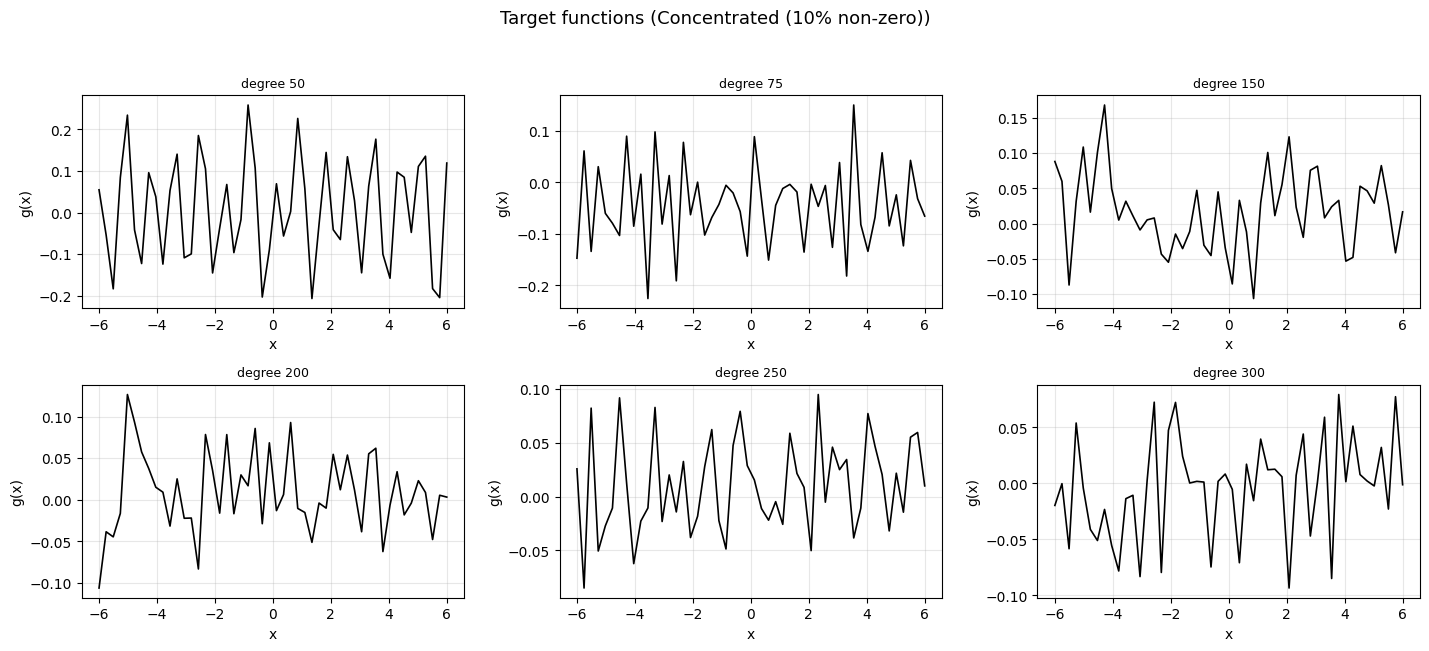

In [ ]:
plot_target_grid("concentrated")

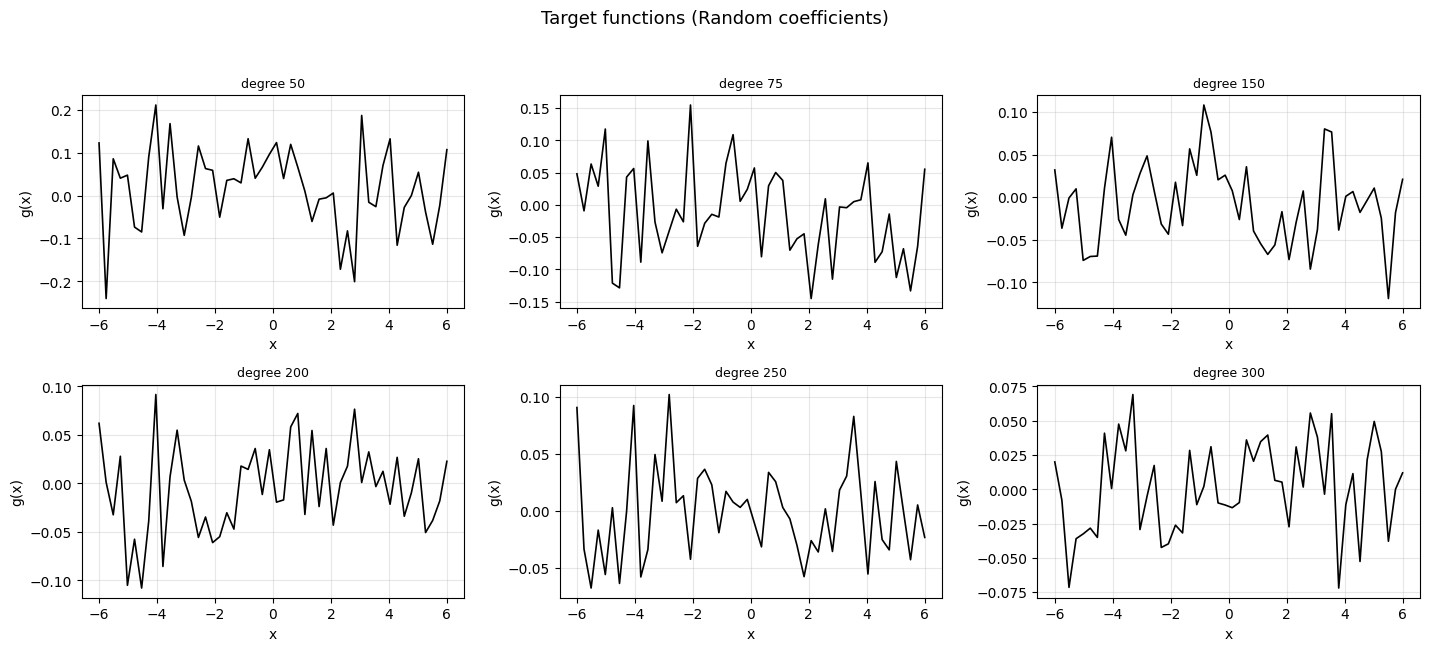

In [ ]:
plot_target_grid("random")

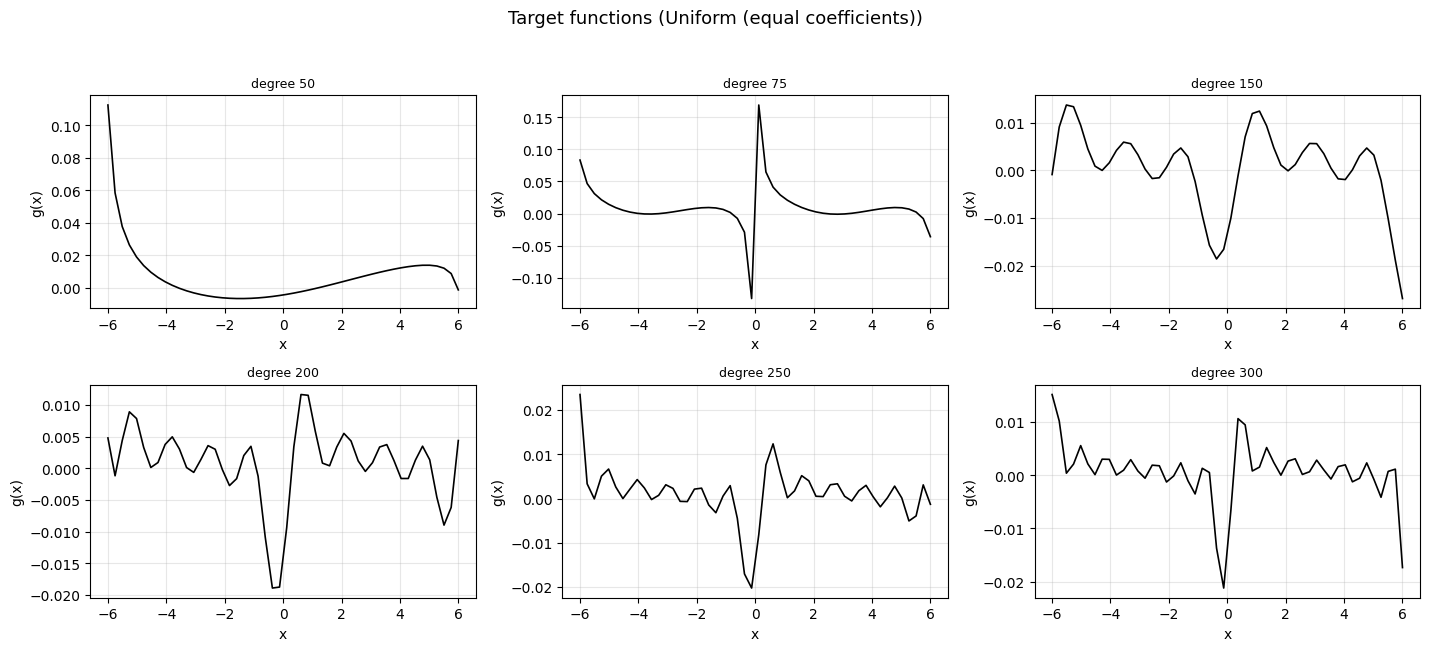

In [ ]:
plot_target_grid("uniform")

## 4. Steps 1-6 for every degree: target, PQC, train, spectrum from the trained PQC, feature map

In [ ]:
STATE = {}
for case, degree in PAIRS:
    t0 = time.time()
    np.random.seed(SEED)
    # 1-3 target and its 100 grid samples (domain [-6, 6])
    target_function = make_target_nb(degree, case)
    true_coeffs, true_coeff0, true_scaling = target_function.__defaults__
    target_freq_mag = {i + 1: abs(c) for i, c in enumerate(true_coeffs)}
    x = np.linspace(-6, 6, 100, requires_grad=False)
    target_y = np.array([target_function(x_) for x_ in x], requires_grad=False)
    # 2 PQC: 5 qubits, r re-uploads, 3 encoding gates (RX, RY, RZ) per qubit per layer
    r = math.ceil(degree / (3 * NUM_QUBITS)); Dp = 3 * NUM_QUBITS * r
    PQC_circuit, weights, dev = build_random_pqc(mode="sequential", num_qubits=NUM_QUBITS, num_layers=r,
                                                 trainable_block_layers=TRAINABLE_BLOCK_LAYERS, seed=42, encode_prob=0.7)
    # 4 train
    weights, cst = train_pqc(PQC_circuit, weights, x, target_y, target_function=target_function)
    # 5 spectrum read from the TRAINED circuit + FFT check
    omega_tilde_D, _, _ = get_omega_D(PQC_circuit, weights)
    with contextlib.redirect_stdout(io.StringIO()):
        emp_freqs, _coeffs = check_spectrum_numerically(PQC_circuit, weights, onp.array(omega_tilde_D), "")
    fft_ok = set(emp_freqs.tolist()).issubset(set(omega_tilde_D))
    # 6 feature map (your extract_pqc_feature_map) and its check against the circuit
    c_theta, phi_D, omega_D = extract_pqc_feature_map(PQC_circuit, weights)
    xt = onp.linspace(-6, 6, 20)
    recon = max(abs(float(onp.dot(c_theta, phi_D(v))) - float(PQC_circuit(weights, v))) for v in xt)
    om_pos = onp.array([w for w in omega_D if w != 0], float)
    phi_ok = onp.allclose(base_features(xt, om_pos) / math.sqrt(len(omega_D)), onp.array([phi_D(v) for v in xt]))
    # data for the plots
    N = 2 * Dp + 2; xs_f = onp.linspace(0, 2 * onp.pi, N, endpoint=False)
    fc = onp.fft.fft(onp.asarray(pqc_eval(PQC_circuit, weights, xs_f))) / N; nf = onp.fft.fftfreq(N, d=1.0 / N).astype(int)
    o = onp.argsort(nf); n_fft, mag_fft = nf[o], onp.abs(fc[o])
    halfw = 2 * math.pi * 4 / max(k for k, v in target_freq_mag.items() if v > 0) / 2          # zoom window: ~4 periods of the top target frequency
    win = onp.linspace(-halfw, halfw, 600)
    STATE[(case, degree)] = dict(target_function=target_function, true_coeff0=true_coeff0, target_freq_mag=target_freq_mag,
                         x=onp.asarray(x), target_y=onp.asarray(target_y), r=r, Dp=Dp, cst=cst, omega_D=omega_D,
                         omega_tilde_D=omega_tilde_D, n_fft=n_fft, mag_fft=mag_fft, win=win,
                         pqc_grid=onp.asarray(pqc_eval(PQC_circuit, weights, x)), pqc_win=onp.asarray(pqc_eval(PQC_circuit, weights, win)),
                         k=sum(v > 0 for v in target_freq_mag.values()),
                         pqc_pool=onp.asarray(pqc_eval(PQC_circuit, weights, onp.linspace(-6, 6, POOL_PER_DEG * Dp))))   # trained PQC on the KRR pool
    print(f"{case:12s} degree {degree:3d}: {NUM_QUBITS} qubits x {r:2d} re-uploads (Omega 0..{Dp}) | non-zero coeffs {STATE[(case, degree)]['k']:3d} | "
          f"final train RMS {math.sqrt(2 * cst[-1]):.3f} | FFT within Omega: {fft_ok} | "
          f"feature map vs circuit {recon:.1e} | phi_D matches: {phi_ok} | {time.time() - t0:.0f}s")

concentrated degree  50: 5 qubits x  4 re-uploads (Omega 0..60) | non-zero coeffs   5 | final train RMS 0.104 | FFT within Omega: True | feature map vs circuit 1.1e-15 | phi_D matches: True | 79s
concentrated degree  75: 5 qubits x  5 re-uploads (Omega 0..75) | non-zero coeffs   8 | final train RMS 0.080 | FFT within Omega: True | feature map vs circuit 1.5e-15 | phi_D matches: True | 91s
concentrated degree 150: 5 qubits x 10 re-uploads (Omega 0..150) | non-zero coeffs  15 | final train RMS 0.061 | FFT within Omega: True | feature map vs circuit 1.1e-15 | phi_D matches: True | 174s
concentrated degree 200: 5 qubits x 14 re-uploads (Omega 0..210) | non-zero coeffs  20 | final train RMS 0.054 | FFT within Omega: True | feature map vs circuit 2.1e-15 | phi_D matches: True | 241s
concentrated degree 250: 5 qubits x 17 re-uploads (Omega 0..255) | non-zero coeffs  25 | final train RMS 0.064 | FFT within Omega: True | feature map vs circuit 2.5e-15 | phi_D matches: True | 295s
concentrated d

## 5. Steps 7-9: weights (guesses and KTA), re-weighted kernel, KRR sweep

In [ ]:
def make_variants(Dp, target_freq_mag, true_coeff0):
    """Step 7: the hand-chosen weights from your script. Unspecified frequencies get FLOOR (never fully switched off)."""
    om = omegas_pos                                          # global, as in your build_w
    active = {k for k, v in target_freq_mag.items() if v > 0}
    off = [k for k in range(1, Dp + 1) if k not in active]   # frequencies the target does not use
    V = {}
    V["Uniform (w=1)"]       = build_w(1.0, onp.ones(len(om)))
    V["Ideal (|true coeffs|)"] = build_w(abs(true_coeff0), target_freq_mag, default=1e-8)
    if off:                                                  # empty when every coefficient is non-zero (random / uniform targets) -> variant is undefined, skipped
        V["no overlap (only off-target ω)"] = build_w(0.0, {k: 1.0 for k in off}, default=0.0)
    V["decay 1/√ω"]          = build_w(1.0, 1 / onp.sqrt(om))
    V["low-pass (ω ≤ D/4)"]  = build_w(1.0, {k: 1.0 for k in range(1, Dp // 4 + 1)}, default=FLOOR)
    V["band (D/4 ≤ ω ≤ 3D/4)"] = build_w(FLOOR, {k: 1.0 for k in range(Dp // 4, 3 * Dp // 4 + 1)}, default=FLOOR)
    V["C1: spikes ω=1,3"]    = build_w(1.0, {1: 0.2, 3: 0.5}, default=FLOOR)
    return V

RES = {}
for case, degree in PAIRS:
    t0 = time.time(); S = STATE[(case, degree)]
    omegas_pos = onp.array([w for w in S["omega_D"] if w != 0], float)            # Omega_D^+ from the trained PQC (your notebook's name)
    Dp, target_function = S["Dp"], S["target_function"]
    P = POOL_PER_DEG * Dp
    pool = onp.linspace(-6, 6, P); y_pool = onp.asarray(target_function(pool), float)
    Base_pool = base_features(pool, omegas_pos)
    perm = onp.random.default_rng(1000 + degree).permutation(P)                    # nested training subsets: first M of this permutation
    V = make_variants(Dp, S["target_freq_mag"], S["true_coeff0"])
    names = list(V) + ["KTA-learned"]
    Ms = sorted({m for m in (max(MIN_M, int(round(f * Dp))) for f in M_FRACTIONS) if m < MAX_M} | {MAX_M})   # sweep ends at MAX_M
    #assert MAX_M < P, "MAX_M must leave test points in the pool"
    res = {n: [] for n in names}; pqc_res = []
    kta_w, kta_A = {}, {}
    for M in Ms:
        tr, te = perm[:M], perm[M:]                                                # train on M pool points, test on the rest
        BaseM, yM, BaseE, yE = Base_pool[tr], y_pool[tr], Base_pool[te], y_pool[te]
        wk, A = kta_weights_fast(pool[tr], yM, omegas_pos)                         # training data only
        kta_w[M], kta_A[M] = wk, A
        pqc_res.append(float(onp.sqrt(onp.mean((S["pqc_pool"][te] - yE) ** 2))))   # trained PQC on the SAME held-out points as KRR
        for n in names:
            w = wk if n == "KTA-learned" else V[n]
            cf, beta = krr_fit(w, BaseM, yM)
            res[n].append(float(onp.sqrt(onp.mean(((BaseE * cf) @ beta - yE) ** 2))))
    RES[(case, degree)] = dict(Ms=Ms, res=res, pqc_res=pqc_res, kta_w=kta_w, kta_A=kta_A, omegas_pos=omegas_pos, V=V)
    print(f"{case:12s} degree {degree:3d}: {len(names)} weight choices x {len(Ms)} values of M (up to {Ms[-1]})  [{time.time() - t0:.0f}s]")

def first_M(Ms, rm, tol=1e-2):
    return next((m for m, e in zip(Ms, rm) if e < tol), None)
print(f"\nSmallest M with RMSE < 1e-2  (None = not reached up to M = {MAX_M})")
for case in CASES:
    print(f"  {CASE_LABEL[case]}")
    for degree in DEGREES:
        d = RES[(case, degree)]; special = ("Uniform (w=1)", "Ideal (|true coeffs|)", "KTA-learned", "no overlap (only off-target ω)")
        others = [first_M(d["Ms"], v) for n, v in d["res"].items() if n not in special]
        others = [m for m in others if m is not None]
        print(f"    degree {degree:3d}:  Ideal {first_M(d['Ms'], d['res']['Ideal (|true coeffs|)'])}   KTA {first_M(d['Ms'], d['res']['KTA-learned'])}   "
              f"Uniform {first_M(d['Ms'], d['res']['Uniform (w=1)'])}   best other guess {min(others) if others else None}")


concentrated degree  50: 8 weight choices x 13 values of M (up to 400)  [1s]
concentrated degree  75: 8 weight choices x 12 values of M (up to 400)  [1s]
concentrated degree 150: 8 weight choices x 11 values of M (up to 400)  [2s]
concentrated degree 200: 8 weight choices x 10 values of M (up to 400)  [2s]
concentrated degree 250: 8 weight choices x 10 values of M (up to 400)  [5s]
concentrated degree 300: 8 weight choices x 9 values of M (up to 400)  [2s]
random       degree  50: 8 weight choices x 13 values of M (up to 400)  [1s]
random       degree  75: 7 weight choices x 12 values of M (up to 400)  [1s]
random       degree 150: 7 weight choices x 11 values of M (up to 400)  [1s]
random       degree 200: 8 weight choices x 10 values of M (up to 400)  [2s]
random       degree 250: 8 weight choices x 10 values of M (up to 400)  [2s]
random       degree 300: 7 weight choices x 9 values of M (up to 400)  [4s]
uniform      degree  50: 8 weight choices x 13 values of M (up to 400)  [1s]
u

## 6. Plots: one cell per category, each cell draws one 2 x 3 figure per target type (6 panels = the 6 degrees)

In [ ]:
def finish(fig, name, bottom=0.0):
    top = 0.95 if fig._suptitle is not None else 1.0
    fig.tight_layout(rect=(0, bottom, 1, top))
    if SAVE_DIR:
        import os; os.makedirs(SAVE_DIR, exist_ok=True); fig.savefig(f"{SAVE_DIR}/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def make_case_grid(w=4.8, h=3.3, **kw):
    """2-row by 3-column grid of subplots: one panel per degree in DEGREES (6 degrees)."""
    fig, axes = plt.subplots(2, 3, figsize=(w * 3, h * 2), squeeze=False, **kw)
    return fig, axes

def case_panels(axes):
    """Yields (ax, degree), filling the 2 x 3 grid row by row."""
    for i, degree in enumerate(DEGREES):
        r, c = divmod(i, 3)
        yield axes[r][c], degree

def shared_legend(fig, ax, ncol=4, fontsize=8):
    """One legend for the whole figure, taken from ax, placed under the panels. Returns the bottom margin to pass to finish()."""
    h, l = ax.get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=ncol, fontsize=fontsize, frameon=False)
    return (0.28 * math.ceil(len(l) / ncol) + 0.15) / fig.get_figheight()

def target_rms(S, n=None):
    """RMS of the target itself on [-6, 6]: the error of a model that always predicts 0 ("not learning" level)."""
    xs = onp.linspace(-6, 6, n or 10 * S["Dp"])
    return float(onp.sqrt(onp.mean(onp.asarray(S["target_function"](xs), float) ** 2)))

HIGHLIGHT = {"Uniform (w=1)": ("tab:blue", "o", 3.0), "Ideal (|true coeffs|)": ("tab:orange", "s", 3.0), "KTA-learned": ("black", "*", 3.0)}
OTHER_COLORS = ["tab:green", "limegreen", "olive", "darkgreen", "tab:purple", "violet", "tab:red", "tab:brown",
                "tab:cyan", "deeppink", "gold", "tab:gray", "navy"]
OTHER_MARKS = ["^", "D", "v", "P", "X", "<", ">", "h", "p", "8", "d", "H", "*"]

ALL_NAMES = list(RES[(CASES[0], DEGREES[0])]["res"])          # the first case has every variant (the others may skip "no overlap")
_others = [n for n in ALL_NAMES if n not in HIGHLIGHT]
STYLE = {n: HIGHLIGHT[n] if n in HIGHLIGHT else (OTHER_COLORS[_others.index(n) % len(OTHER_COLORS)], OTHER_MARKS[_others.index(n) % len(OTHER_MARKS)], 1.3) for n in ALL_NAMES}

def draw_errors(ax, case, degree, include_kta):
    d = RES[(case, degree)]
    for n, v in d["res"].items():
        if n == "KTA-learned" and not include_kta: continue
        c, m, lw = STYLE[n]
        z, a = (5, 1.0) if n in HIGHLIGHT else (2, 0.85)
        ax.plot(d["Ms"], v, marker=m, color=c, lw=lw, ms=5, zorder=z, alpha=a, label=n)
    ax.set_xlim(right=MAX_M * 1.02)
    if LOG_Y: ax.set_yscale("log")
    ax.set_xlabel("number of training samples M"); ax.set_ylabel("RMSE vs target"); ax.grid(alpha=0.3, which="both")
    ax.set_title(f"degree {degree}", fontsize=9)

def error_grid_by_case(include_kta):
    """One 2 x 3 figure per target type."""
    for case in CASES:
        fig, axes = make_case_grid(w=4.8, h=3.6)
        for ax, degree in case_panels(axes): draw_errors(ax, case, degree, include_kta)
        fig.suptitle("KRR sample efficiency: hand-chosen weights" + (" vs KTA-learned w" if include_kta else "") + f" ({CASE_LABEL[case]}, M up to {MAX_M})", fontsize=13)
        finish(fig, f"errors_{'with_kta' if include_kta else 'variants'}_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=5))

### 6.0 The target functions

### 6.1 Trained PQC vs target (step 4)

In [ ]:
def plot_pqc_fit_grid(case):                                    # 6.1
    fig, axes = make_case_grid(w=4.8, h=3.3)
    for ax, degree in case_panels(axes):
        S = STATE[(case, degree)]
        if FIT_VIEW == "grid100":
            ax.plot(S["x"], S["target_y"], c="black", linewidth=2.5, label="target function")
            ax.scatter(S["x"], S["target_y"], s=10, facecolor="white", edgecolor="black", label="sampled points")
            ax.plot(S["x"], S["pqc_grid"], c="blue", label="trained PQC")
        else:
            win = S["win"]
            ax.plot(win, onp.asarray(S["target_function"](win), float), c="black", linewidth=2.5, label="target function")
            ax.plot(win, S["pqc_win"], c="blue", label="trained PQC")
            m = (S["x"] >= win[0]) & (S["x"] <= win[-1])
            ax.scatter(S["x"][m], S["target_y"][m], s=10, facecolor="white", edgecolor="black", zorder=5, label="sampled points")
        ax.set_xlabel("x"); ax.set_ylabel("g(x)"); ax.set_title(f"degree {degree}", fontsize=9); ax.grid(alpha=0.3)
    fig.suptitle(f"Trained PQC vs. target function ({CASE_LABEL[case]})", fontsize=13)
    finish(fig, f"pqc_fit_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=3))







### 6.2 Analytic Ω vs spectrum of the trained PQC (step 5)

In [ ]:

def plot_spectrum_grid(case):                                   # 6.2
    floor = 1e-8
    fig, axes = make_case_grid(w=4.8, h=3.3)
    for ax, degree in case_panels(axes):
        S = STATE[(case, degree)]; om = onp.array(S["omega_tilde_D"]); D_ = int(om.max())
        mag_norm = onp.maximum(S["mag_fft"] / S["mag_fft"].max(), floor)
        ax.vlines(om, floor, 1.0, color="lightgray", linewidth=1.0, label=r"accessible $\Omega$ (analytic)")
        ax.stem(S["n_fft"], mag_norm, bottom=floor, basefmt=" ", linefmt="#6C4AB6", markerfmt="#6C4AB6", label=r"simulated $\Omega$ (FFT of trained PQC)")
        ax.set_yscale("log"); ax.set_ylim(floor, 2.0); ax.set_xlim(-D_ - 1, D_ + 1)
        ax.set_xlabel("frequency $n$"); ax.set_ylabel(r"normalized $|c_n|$"); ax.set_title(f"degree {degree}", fontsize=9)
    fig.suptitle(f"Analytic Omega vs spectrum of trained PQC ({CASE_LABEL[case]})", fontsize=13)
    finish(fig, f"spectrum_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=2))

### 6.3 Training cost (step 4)

The dashed line is the error of a model that always predicts 0 (the RMS of the target). A PQC that is learning must get *below* it.

In [ ]:
def plot_training_cost_grid(case):                              # 6.3
    fig, axes = make_case_grid(w=4.4, h=3.1)
    for ax, degree in case_panels(axes):
        S = STATE[(case, degree)]
        ax.plot([math.sqrt(2 * c) for c in S["cst"]], color="tab:blue", label="PQC RMS error on the 100 grid points")
        ax.axhline(float(onp.sqrt(onp.mean(S["target_y"] ** 2))), color="gray", ls="--", lw=1.2, label="predict-zero level (RMS of the target)")
        ax.set_xlabel("optimisation step"); ax.set_ylabel("RMS cost"); ax.set_title(f"degree {degree}", fontsize=9); ax.grid(alpha=0.3)
    fig.suptitle(f"RMS cost during optimisation ({CASE_LABEL[case]})", fontsize=13)
    finish(fig, f"training_cost_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=2))


### 6.4 Error plots: weight variants only (no KTA)

### 6.5 Error plots: weight variants and the KTA-learned w

In [ ]:
def plot_errors_grid(case, include_kta):                        # 6.4 (include_kta=False) and 6.5 (include_kta=True)
    fig, axes = make_case_grid(w=4.8, h=3.6)
    for ax, degree in case_panels(axes): draw_errors(ax, case, degree, include_kta)
    fig.suptitle("KRR sample efficiency: hand-chosen weights" + (" vs KTA-learned w" if include_kta else "") + f" ({CASE_LABEL[case]}, M up to {MAX_M})", fontsize=13)
    finish(fig, f"errors_{'with_kta' if include_kta else 'variants'}_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=5))

### 6.6 Trained PQC vs KRR with the KTA-learned w

The PQC is trained once, so its error does not depend on M: it is evaluated on the same held-out points as KRR at each M. The dashed line is the predict-zero level.

In [ ]:
def plot_pqc_vs_kta_grid(case):                                 # 6.6
    fig, axes = make_case_grid(w=4.8, h=3.3)
    for ax, degree in case_panels(axes):
        d, S = RES[(case, degree)], STATE[(case, degree)]
        ax.plot(d["Ms"], d["pqc_res"], color="#6C4AB6", marker="o", ms=4, lw=1.8, label="trained PQC")
        ax.plot(d["Ms"], d["res"]["KTA-learned"], color="black", marker="*", ms=6, lw=2.0, label="KRR with KTA-learned w")
        ax.axhline(target_rms(S), color="gray", ls="--", lw=1.2, label="predict-zero level (RMS of the target)")
        ax.set_xlim(right=MAX_M * 1.02)
        if LOG_Y: ax.set_yscale("log")
        ax.set_xlabel("number of training samples M"); ax.set_ylabel("RMSE vs target"); ax.grid(alpha=0.3, which="both"); ax.set_title(f"degree {degree}", fontsize=9)
    fig.suptitle(f"Trained PQC vs KRR with KTA-learned w ({CASE_LABEL[case]}, M up to {MAX_M})", fontsize=13)
    finish(fig, f"pqc_vs_kta_rmse_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=3))

### 6.7 KTA-learned w vs the target's coefficient magnitudes (largest M)

In [ ]:
def unit(v):
    v = onp.abs(onp.asarray(v, float)); return v / onp.linalg.norm(v)

def plot_kta_w_grid(case):                                      # 6.7
    fig, axes = make_case_grid(w=4.8, h=3.3)
    for ax, degree in case_panels(axes):
        d, S = RES[(case, degree)], STATE[(case, degree)]; M_big = d["Ms"][-1]
        om_all = onp.concatenate([[0], d["omegas_pos"]]).astype(int)
        target_vec = onp.array([abs(S["true_coeff0"])] + [S["target_freq_mag"].get(int(o), 0.0) for o in d["omegas_pos"]])
        bw = 0.4; xp = onp.arange(len(om_all))
        ax.bar(xp - bw / 2, unit(d["kta_w"][M_big]), width=bw, color="tab:blue", label="KTA-learned w")
        ax.bar(xp + bw / 2, unit(target_vec), width=bw, color="tab:orange", label="target amplitude")
        step = max(1, len(om_all) // 12); ax.set_xticks(xp[::step]); ax.set_xticklabels(om_all[::step], fontsize=7)
        ax.set_xlabel("frequency ω"); ax.set_ylabel("magnitude (unit L2 norm)"); ax.grid(alpha=0.3, axis="y")
        ax.set_title(f"degree {degree}  (M={M_big}, alignment {d['kta_A'][M_big]:.3f})", fontsize=9)
    fig.suptitle(f"KTA-learned w vs the target's coefficient magnitudes ({CASE_LABEL[case]}, largest M)", fontsize=13)
    finish(fig, f"kta_w_grid_{case}", bottom=shared_legend(fig, axes[0][0], ncol=2))

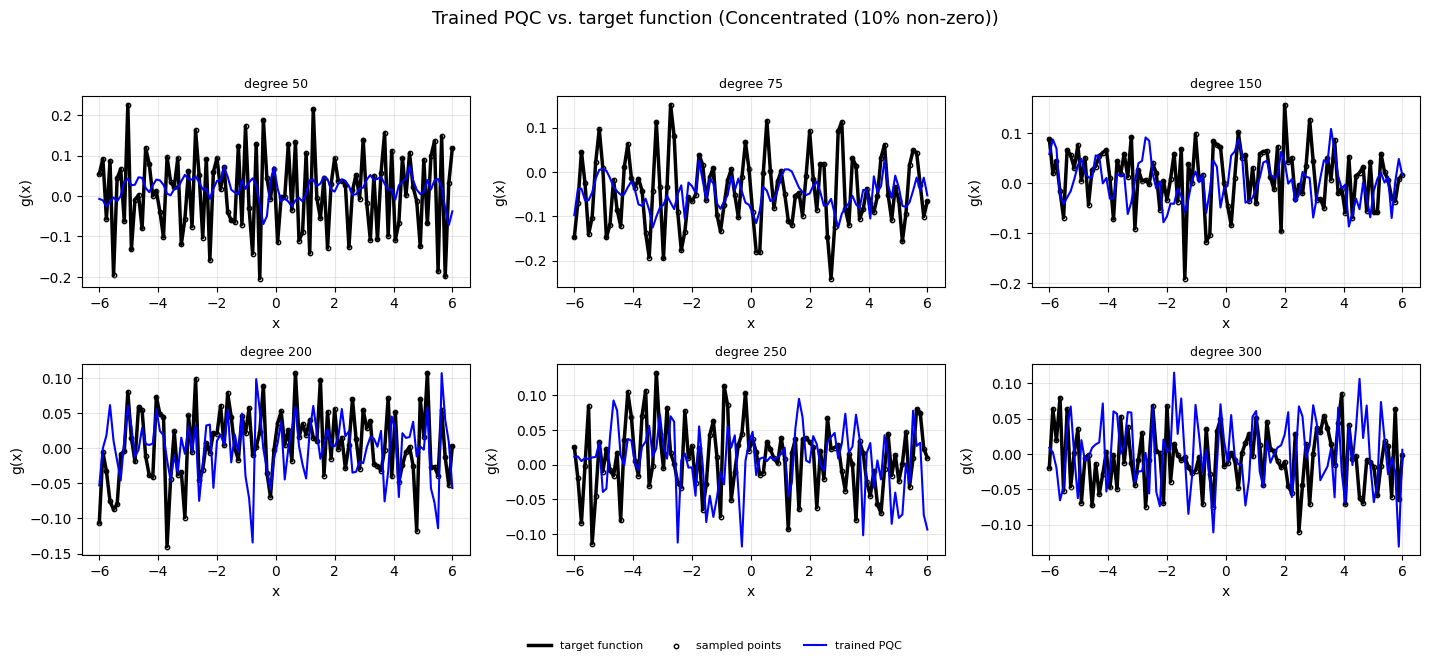

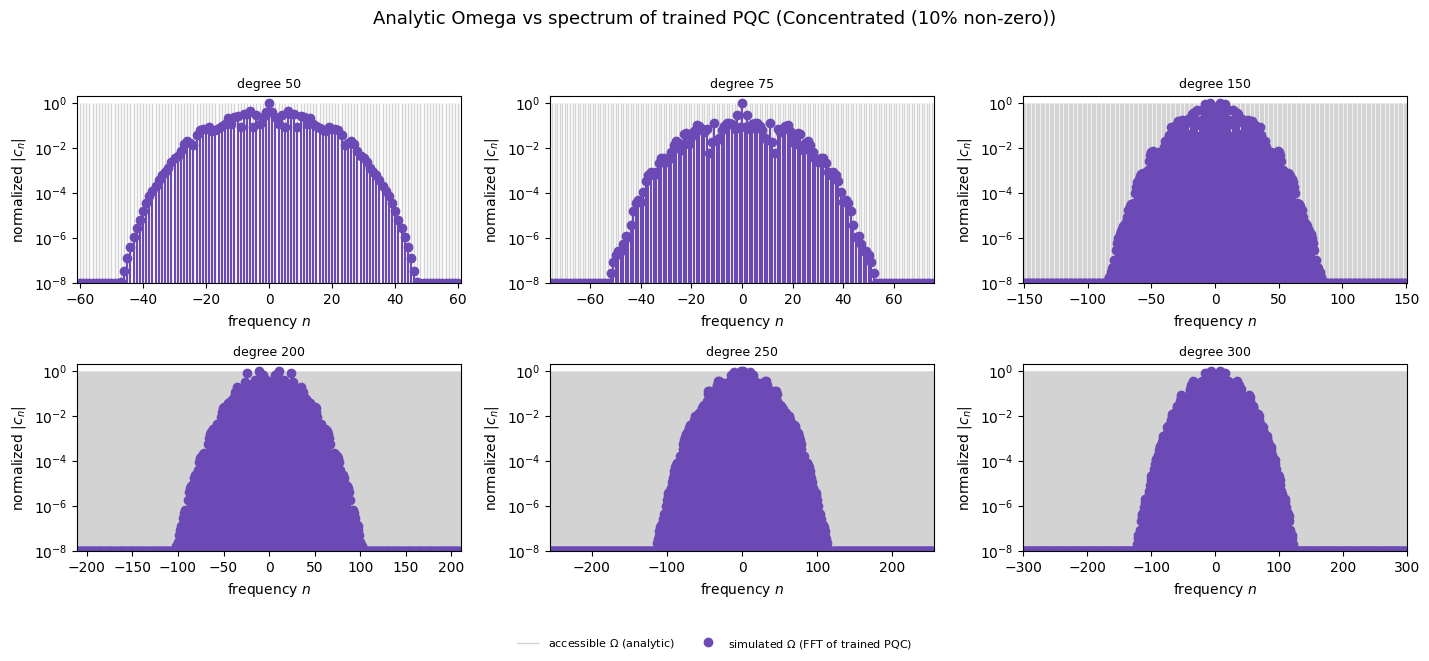

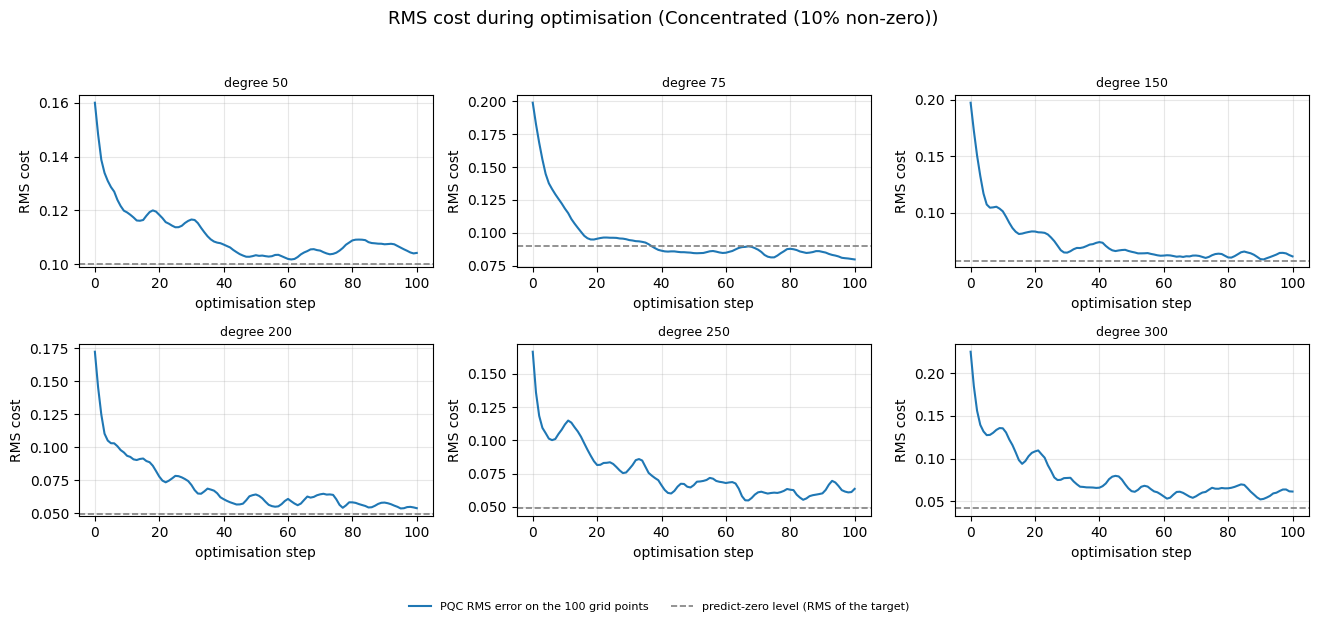

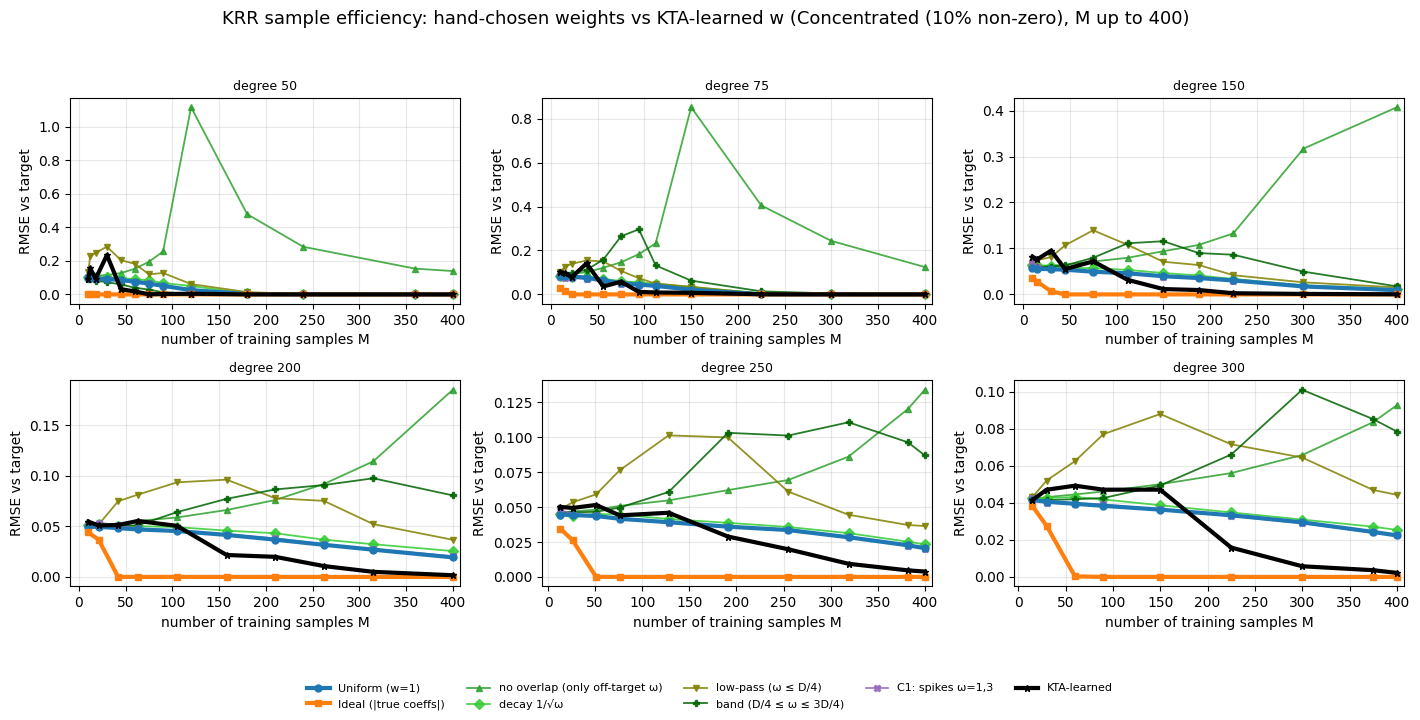

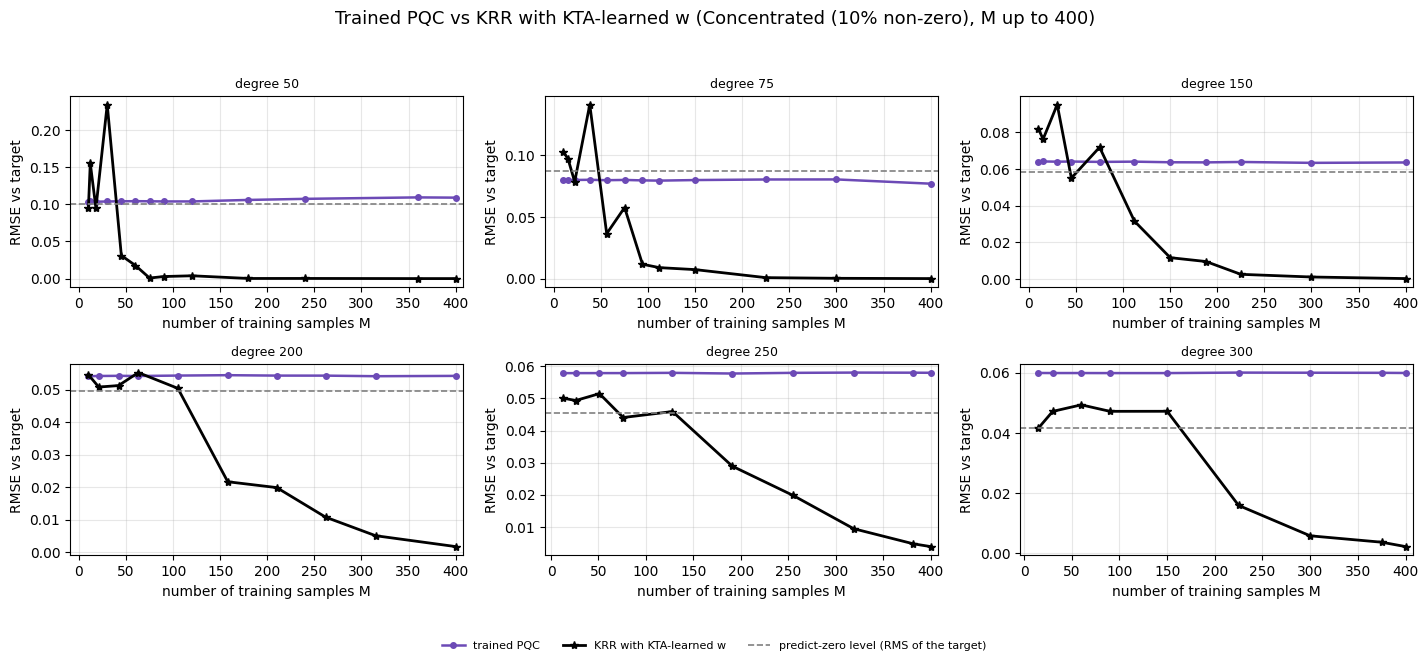

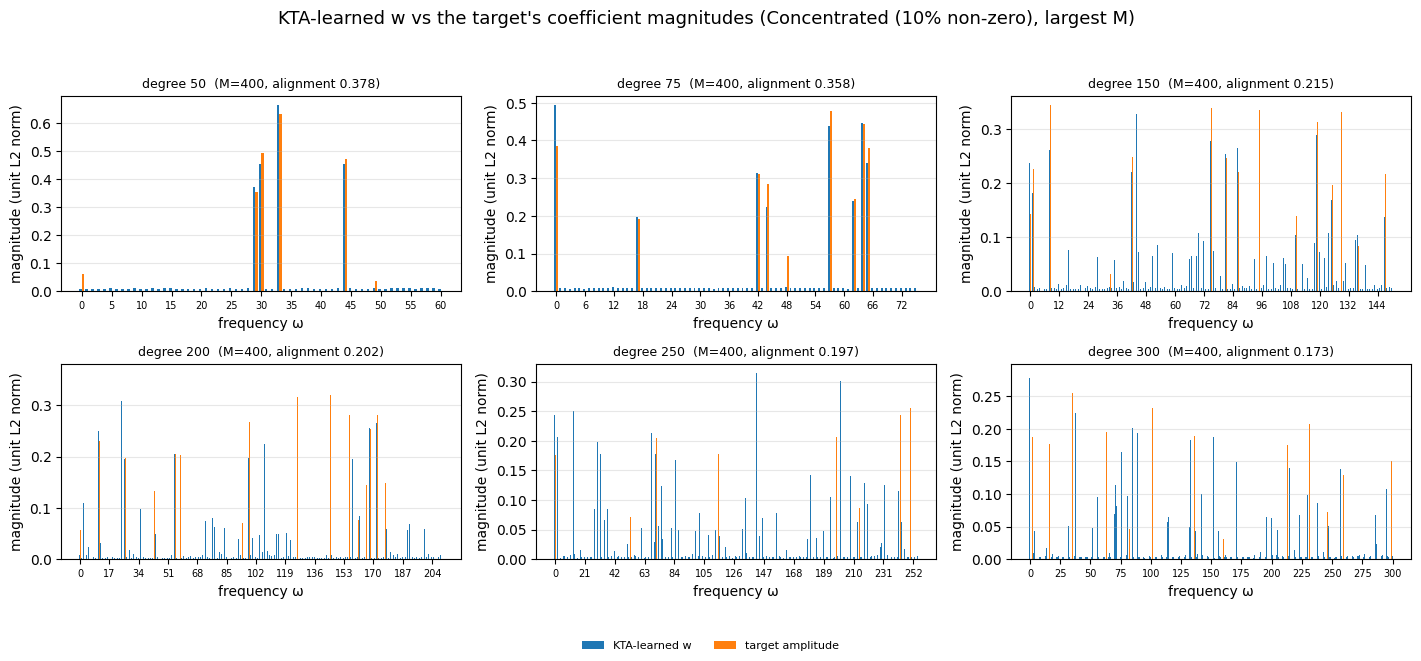

In [ ]:
plot_pqc_fit_grid("concentrated")        # 6.1   (then "random", "uniform")
plot_spectrum_grid("concentrated")       # 6.2   (then "random", "uniform")
plot_training_cost_grid("concentrated")  # 6.3   (then "random", "uniform")
#plot_errors_grid("concentrated", include_kta=False)   # 6.4   (then "random", "uniform")
plot_errors_grid("concentrated", include_kta=True)    # 6.5   (then "random", "uniform")
plot_pqc_vs_kta_grid("concentrated")     # 6.6   (then "random", "uniform")
plot_kta_w_grid("concentrated")          # 6.7   (then "random", "uniform")

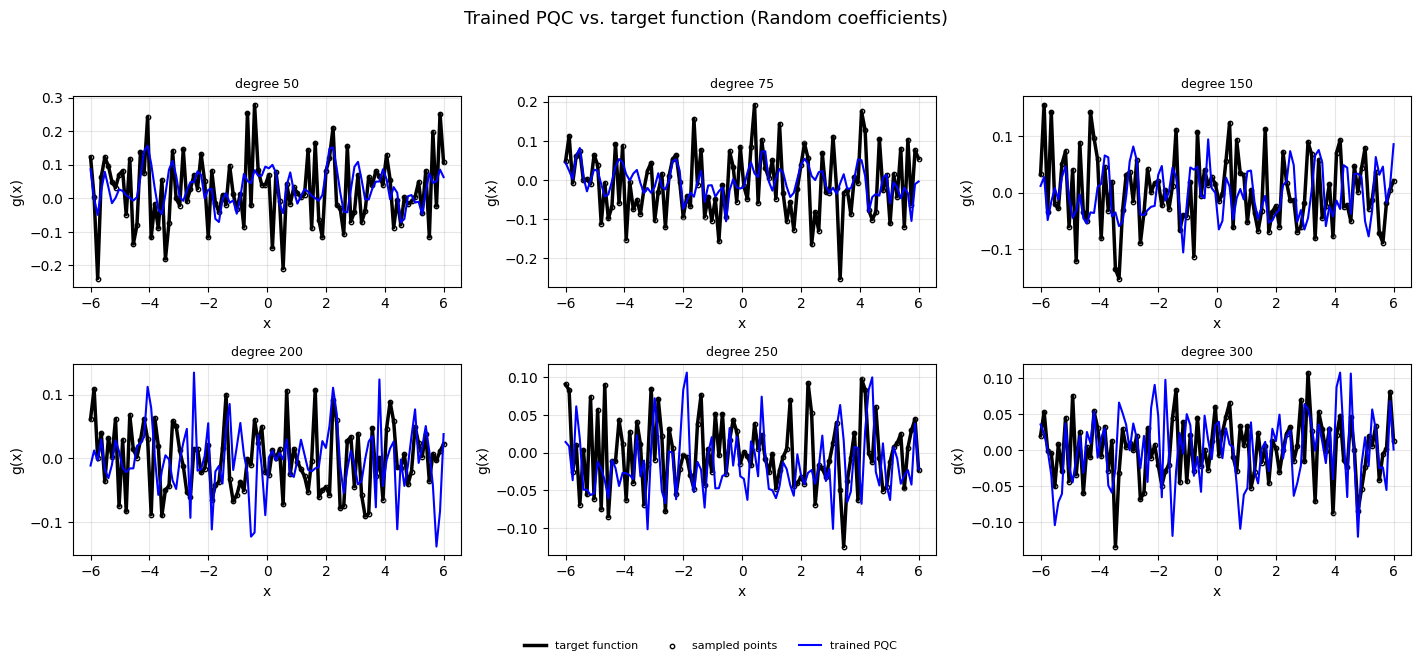

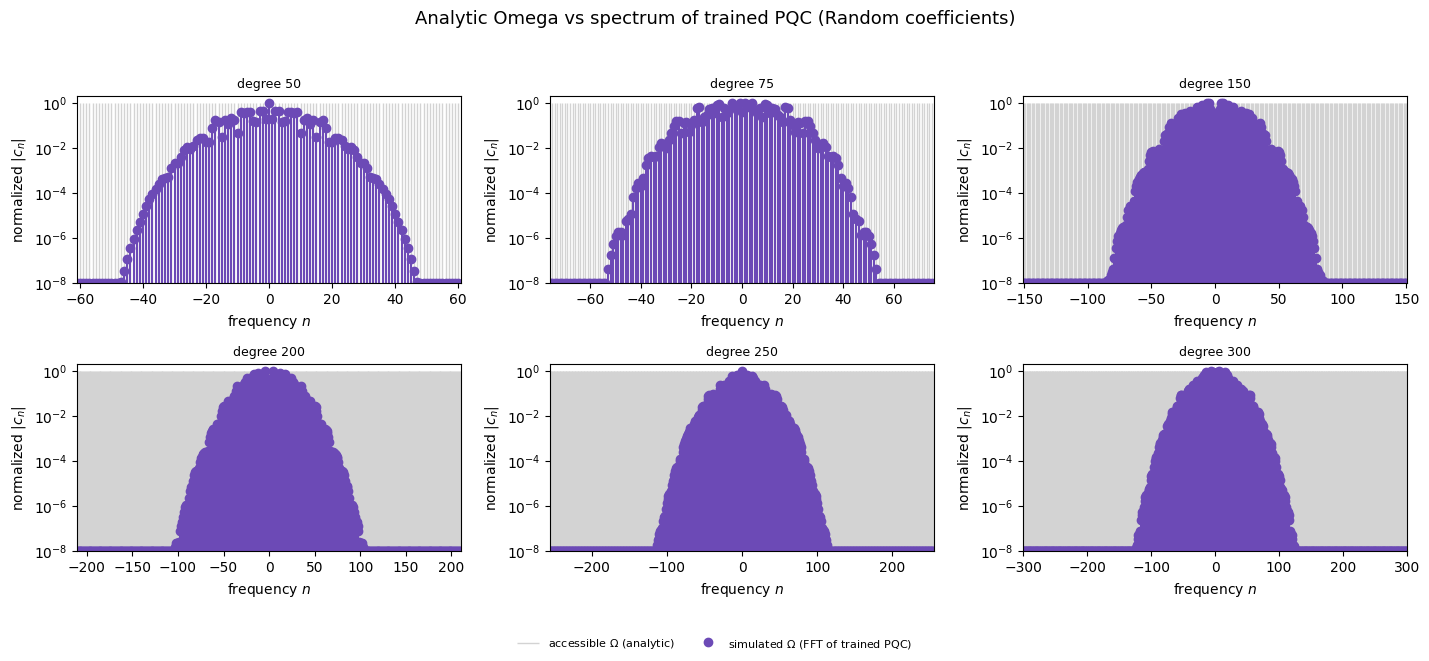

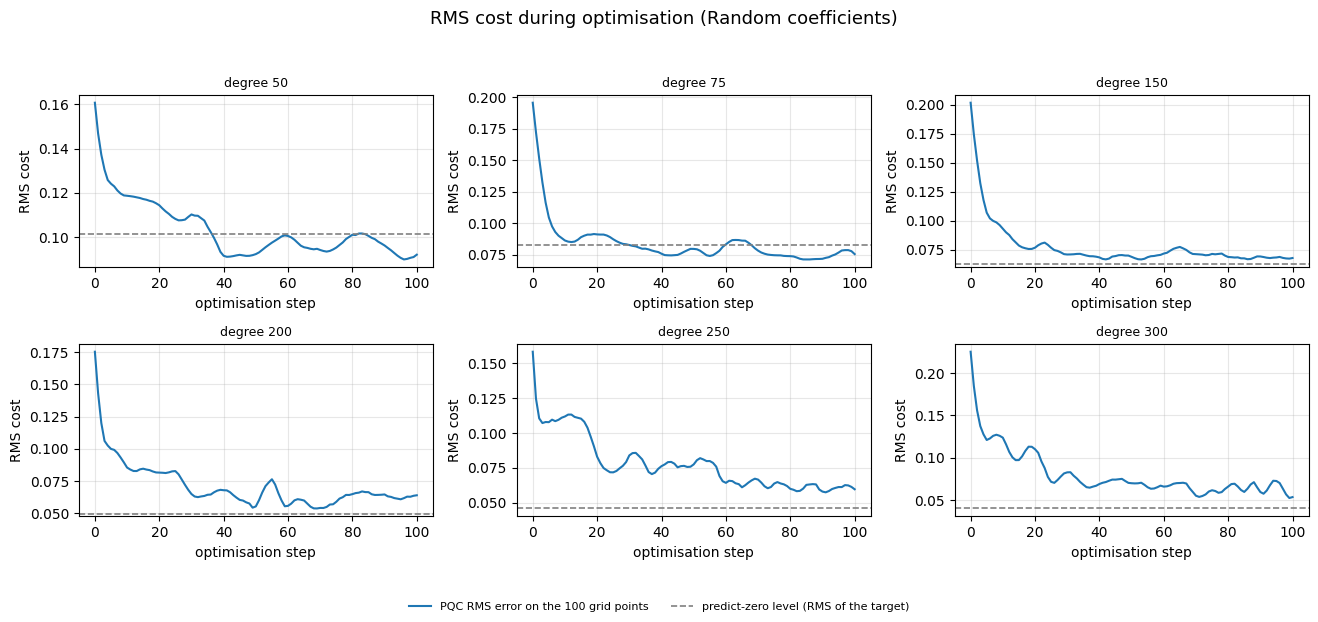

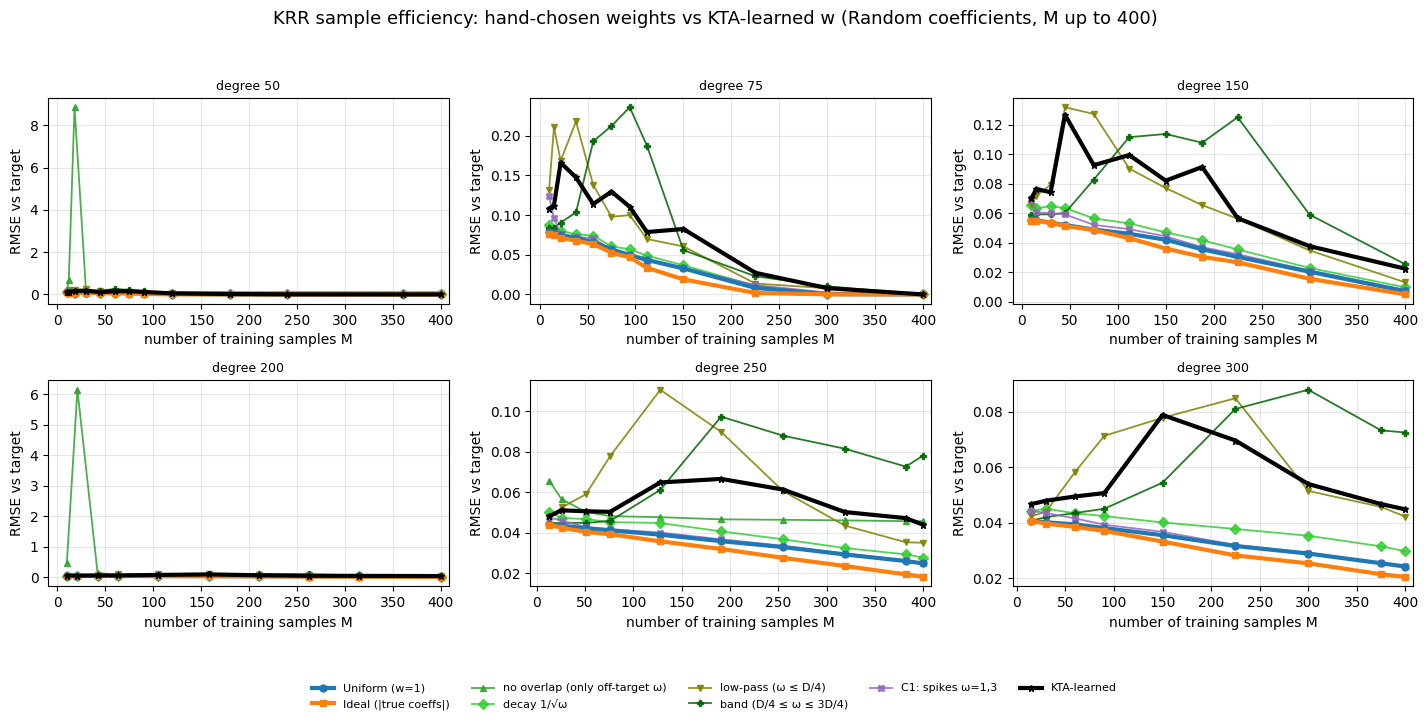

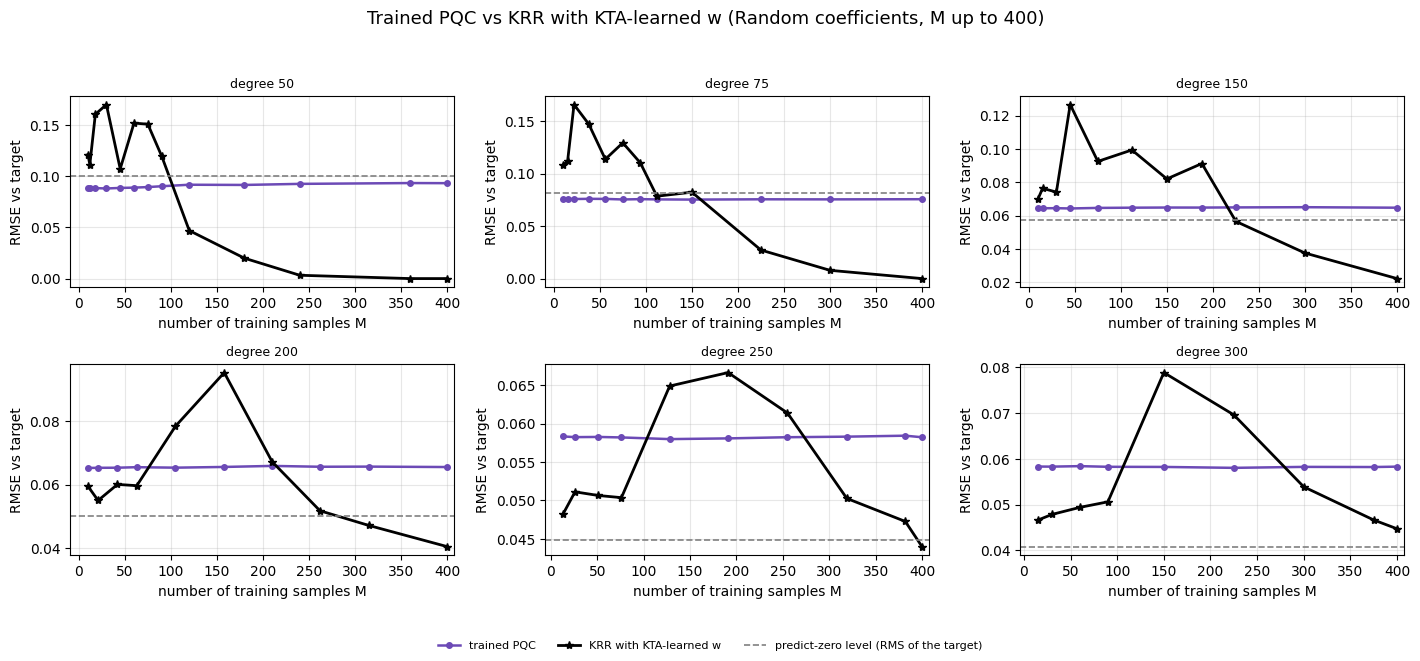

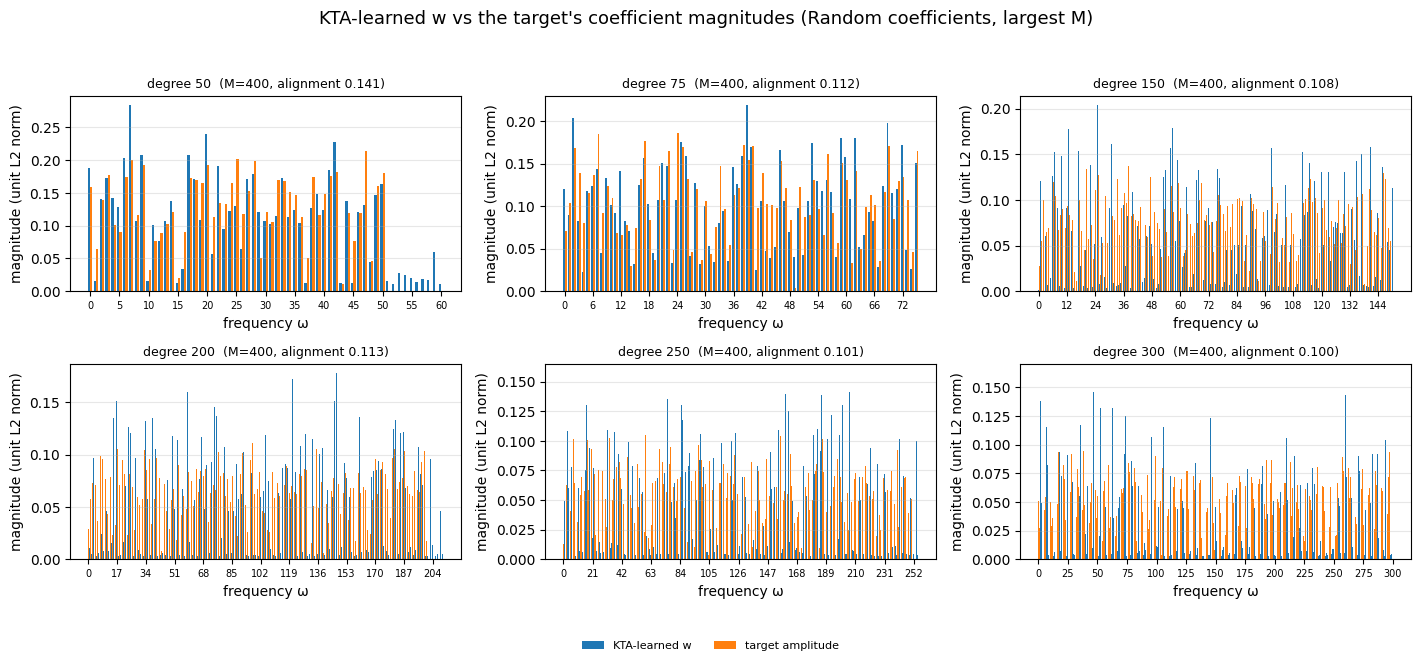

In [ ]:
plot_pqc_fit_grid("random")
plot_spectrum_grid("random")
plot_training_cost_grid("random")
#plot_errors_grid("concentrated", include_kta=False)   # 6.4   (then "random", "uniform")
plot_errors_grid("random", include_kta=True)
plot_pqc_vs_kta_grid("random")
plot_kta_w_grid("random")

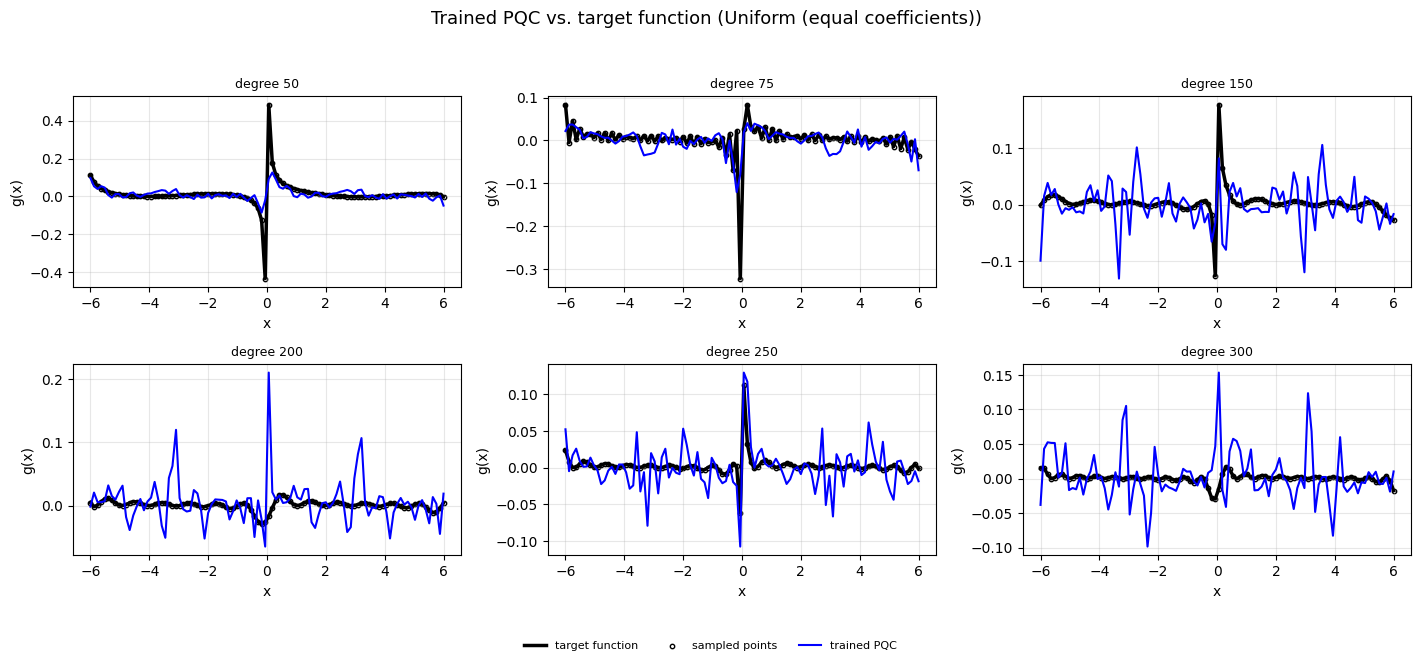

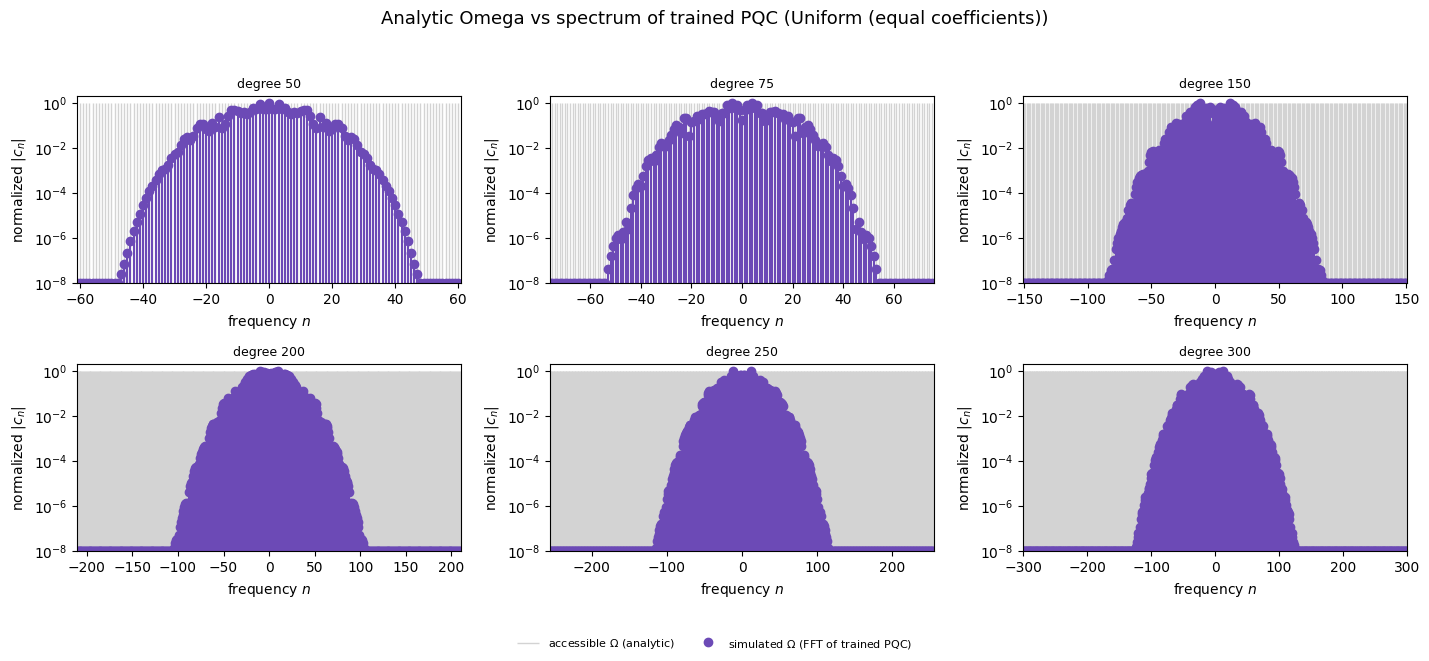

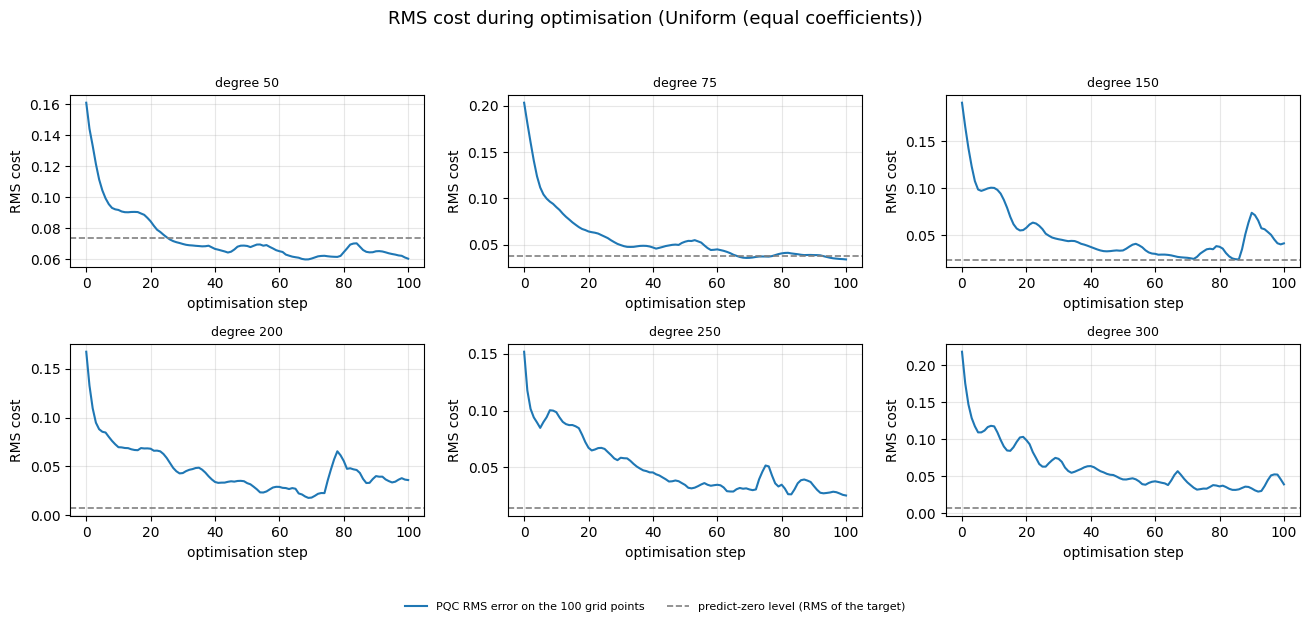

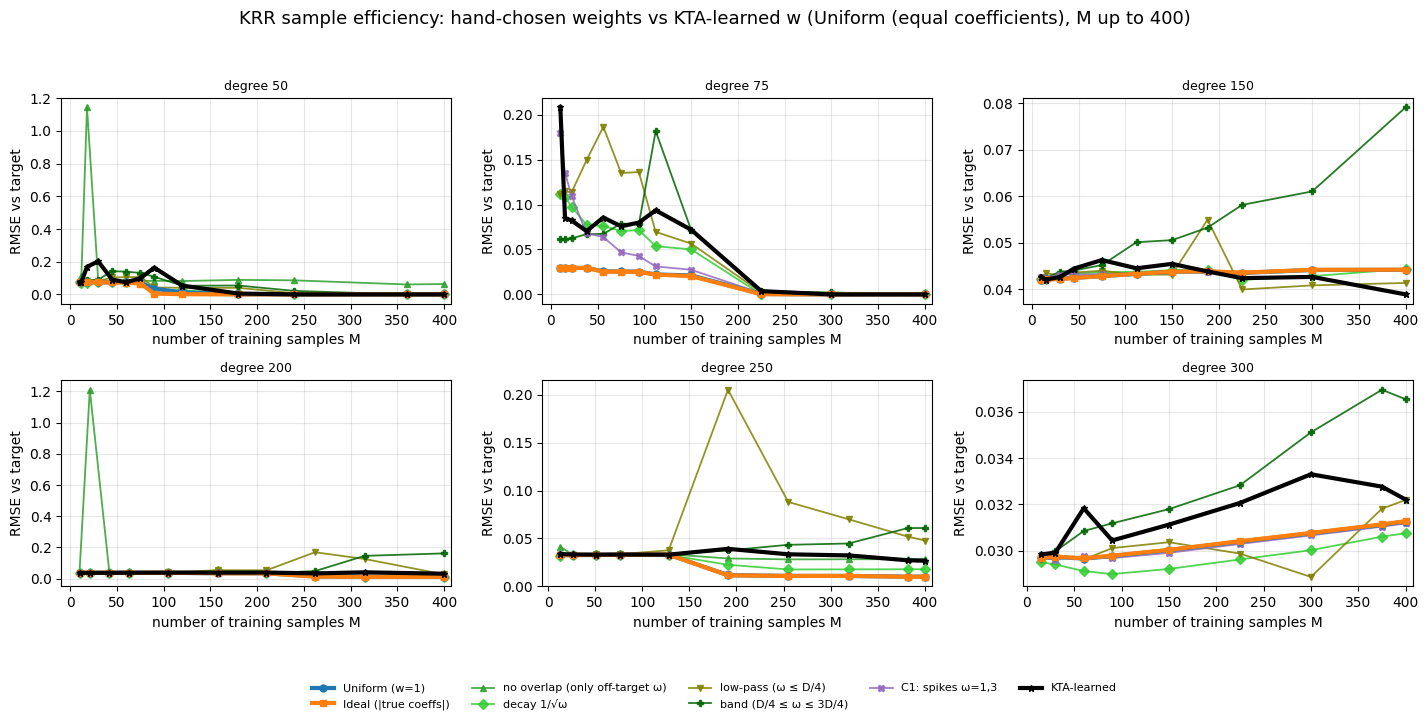

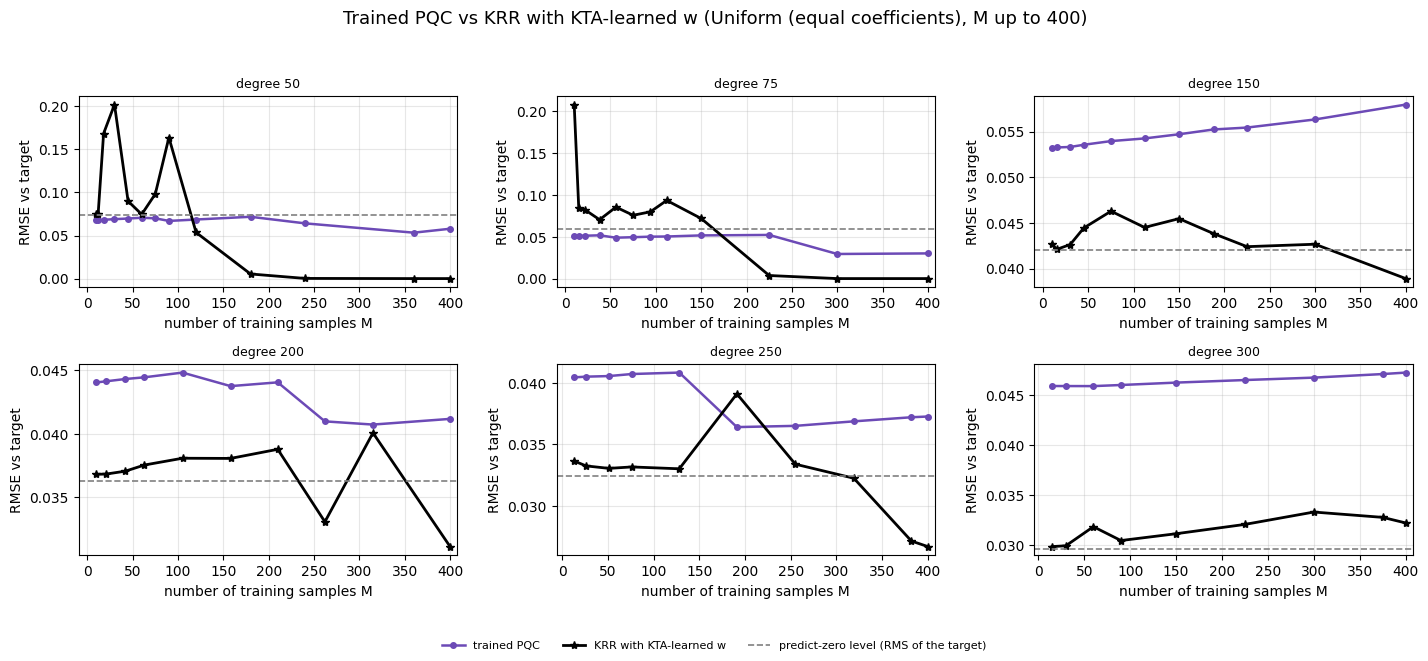

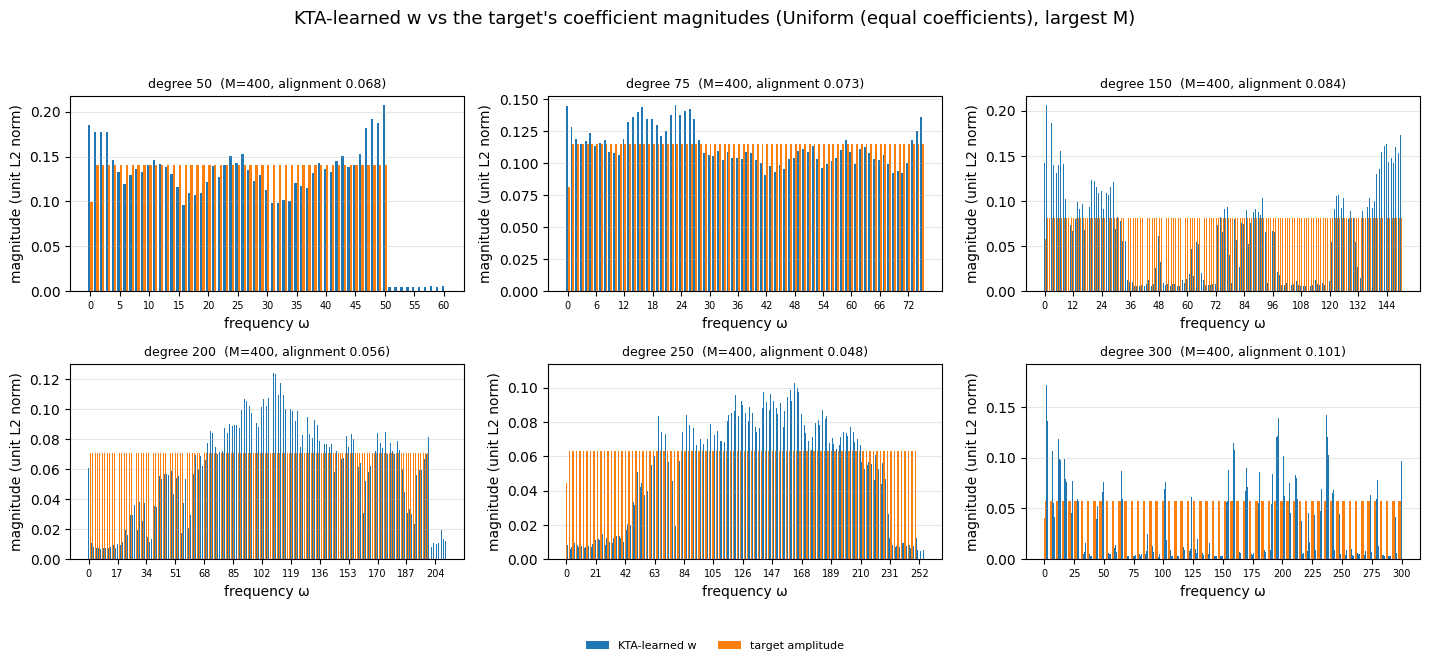

In [ ]:
plot_pqc_fit_grid("uniform")
plot_spectrum_grid("uniform")
plot_training_cost_grid("uniform")
#plot_errors_grid("uniform", include_kta=False)
plot_errors_grid("uniform", include_kta=True)
plot_pqc_vs_kta_grid("uniform")
plot_kta_w_grid("uniform")